# The joint model on India's record

This notebook fits the joint model of `experiments/emdat_damage_model/04_joint_location_damage.ipynb`, the recovery notebook, of where events start and what they cost to EM-DAT's record of hydrometeorological events in India from 1990 to 2023. It maps the fitted rate and its terms, checks the fit against the record, and computes the damage curves the fit gives for India and for each state.

In [1]:
import os

# A JAX Metal plugin is installed, so JAX is pinned to the CPU before anything imports it.
os.environ["JAX_PLATFORMS"] = "cpu"

import warnings

from pathlib import Path

import arviz as az
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import polars as pl
import pymc as pm
import pymc_extras as pmx
import pytensor.tensor as pt
import xarray as xr

from pymc_extras.marginal import recover, unmarginalize
from pymc_extras.model.marginal.distributions.enumerable import NonSeparableLogpWarning
from scipy.spatial import cKDTree
from scipy.special import logit

from climate_risk import load_shapefile
from climate_risk.data.cell_samples import load_cell_distances_to, load_cell_unit_overlaps
from climate_risk.data.gadm import administered_territories, load_units_in_country
from climate_risk.data.geo_disasters import load_resolved_units
from climate_risk.data.ghsl import POPULATION_EPOCHS, population_on_cells
from climate_risk.data.world_bank import load_wb_data
from climate_risk.data_functions.emdat_processing import DISASTER_CLASSES, event_geography, load_emdat_events
from climate_risk.data_functions.rivers_data_loader import load_rivers_data
from climate_risk.geo.crs import PROJECTED_CRS, to_km
from climate_risk.geo.raster import build_cell_grid, dissolve_place_boundary
from climate_risk.models.aggregation import Aggregation
from climate_risk.plotting import configure_plot_style

configure_plot_style()
# Every count, damage report and record entry in a reporting group shares the group's marginalized center and hazard, so each event's
# terms are one joint logp, which pymc_extras files under one of the group's variables and warns about at every compile.
warnings.filterwarnings("ignore", category=NonSeparableLogpWarning)

CACHE_DIR = Path("../../data")
ISO = "IND"
SEED = 20261119

## Geography

As in the recovery notebook: atoms are the cells of a 25 km lattice over India, and each atom belongs to the ADM2 and ADM1 unit covering most of it.

In [2]:
RESOLUTION_KM = 25.0
LEVELS = ("ADM2", "ADM1", "ADM0")

# GADM files the territories India administers in Kashmir and along the Chinese border under codes of their own.
codes = (ISO, *administered_territories(iso=ISO, cache_dir=CACHE_DIR))
units = {level: pd.concat([load_units_in_country(iso=code, level=admin, cache_dir=CACHE_DIR) for code in codes], ignore_index=True)
         for level, admin in [("ADM2", 2), ("ADM1", 1)]}
boundary = dissolve_place_boundary(units["ADM1"][["geometry"]], iso3=ISO)
units["ADM0"] = gpd.GeoDataFrame({"gid": [ISO], "name": ["India"], "admin_level": [0]},
                                 geometry=boundary.geometry.to_numpy(),
                                 crs=boundary.crs)
n_units = {level: len(units[level]) for level in LEVELS}

grid = build_cell_grid(boundary, resolution_km=RESOLUTION_KM)
atoms = grid.cells.reset_index(drop=True)
n_atoms = len(atoms)
column_of_cell = pd.Series(np.arange(n_atoms), index=atoms["cell_id"].to_numpy())

# Every (atom, unit) pair that overlaps, with units as positions into units[level].
overlaps = {}
for level in LEVELS:
    pairs = load_cell_unit_overlaps(grid=grid, units=units[level], cache_dir=CACHE_DIR)
    unit_position = pd.Series(np.arange(n_units[level]), index=units[level]["gid"].to_numpy())
    overlaps[level] = pd.DataFrame({"atom": column_of_cell.loc[pairs["cell_id"]].to_numpy(),
                                    "unit": unit_position.loc[pairs["gid"]].to_numpy(),
                                    "coverage": pairs["coverage"].to_numpy()})

# The unit covering most of each atom, which is the unit an event centered there is reported in.
unit_of_atom = {level: (overlaps[level].sort_values("coverage", ascending=False)
                        .drop_duplicates("atom")
                        .set_index("atom")["unit"]
                        .reindex(np.arange(n_atoms))
                        .to_numpy())
                for level in LEVELS}

pd.Series({"atoms": n_atoms, **{f"{level} units": n_units[level] for level in LEVELS}})

atoms         5607
ADM2 units     676
ADM1 units      41
ADM0 units       1
dtype: int64

## Hazard covariates

These are the recovery notebook's four hazard covariates, each standardized over India's atoms: log distance to the nearest major river in HydroRIVERS, the log average discharge of that river, their product, and log distance to the GSHHG shoreline. Both distances are floored at half an atom.

In [3]:
COVARIATE_NAMES = ("log distance to river", "log discharge of nearest river", "distance by discharge", "log distance to coast")
DISTANCE_FLOOR_KM = RESOLUTION_KM / 2
# The nearest coast of an inland atom lies inside India's bounds widened by this many degrees.
SHORELINE_MARGIN_DEGREES = 5.0


def standardized(values):
    """Values shifted to mean zero and scaled to unit standard deviation."""
    return (values - values.mean()) / values.std()


west, south, east, north = boundary.total_bounds

rivers = load_rivers_data(CACHE_DIR)
nearest_river = load_cell_distances_to(grid=grid,
                                       features=rivers.cx[west - 1:east + 1, south - 1:north + 1],
                                       cache_dir=CACHE_DIR,
                                       return_columns=["DIS_AV_CMS"])
river_km = to_km(nearest_river["distance_to_closest"].to_numpy())

shoreline = load_shapefile(which="coastline", cache_dir=CACHE_DIR).boundary.clip((west - SHORELINE_MARGIN_DEGREES,
                                                                                  south - SHORELINE_MARGIN_DEGREES,
                                                                                  east + SHORELINE_MARGIN_DEGREES,
                                                                                  north + SHORELINE_MARGIN_DEGREES))
nearest_coast = load_cell_distances_to(grid=grid,
                                       features=shoreline[~shoreline.is_empty],
                                       cache_dir=CACHE_DIR)
coast_km = to_km(nearest_coast["distance_to_closest"].to_numpy())

river_distance_z = standardized(np.log(np.maximum(river_km, DISTANCE_FLOOR_KM)))
discharge_z = standardized(np.log(nearest_river["DIS_AV_CMS"].to_numpy()))
covariates = np.column_stack([river_distance_z,
                              discharge_z,
                              river_distance_z * discharge_z,
                              standardized(np.log(np.maximum(coast_km, DISTANCE_FLOOR_KM)))])

pd.DataFrame({"min": covariates.min(axis=0), "max": covariates.max(axis=0)}, index=list(COVARIATE_NAMES)).round(2)

,min,max
log distance to river,-1.23,3.59
log discharge of nearest river,-0.98,4.21
distance by discharge,-5.16,3.16
log distance to coast,-2.45,1.46


## The record

The record is EM-DAT's hydrometeorological events in India from 1990 to 2023: floods, storms and wet mass movements. Each comes with the units it names, its deaths, total affected and CPI-adjusted damage in thousands of US dollars.

Climatological events are left out because their people-affected counts mix two scales. The five droughts among them carry half of everyone EM-DAT counts as affected in India, with counts of 50 to 330 million, the size of whole regions' populations. The heat waves affect a few hundred people.

In [4]:
FIRST_YEAR, LAST_YEAR = 1990, 2023
CLASSES = ["Hydrometeorological"]
DISASTER_TYPES = [disaster_type for disaster_type, disaster_class in DISASTER_CLASSES.items() if disaster_class in CLASSES]

events = load_emdat_events(CACHE_DIR).filter(
    (pl.col("ISO") == ISO)
    & pl.col("Disaster Type").is_in(DISASTER_TYPES)
    & pl.col("date").dt.year().is_between(FIRST_YEAR, LAST_YEAR)
)

resolved = pl.from_pandas(load_resolved_units(isos=[ISO], cache_dir=CACHE_DIR)).select(
    pl.col("DisNo."),
    pl.col("gid"),
    pl.col("name"),
    pl.col("admin_level").cast(pl.Int8),
    pl.col("geocoding_q").cast(pl.Int8),
    pl.col("overlap"),
)
geography = event_geography(events, resolved=resolved)

events.group_by("Disaster Type").len().sort("len", descending=True)

Disaster Type,len
str,u32
"""Flood""",236
"""Storm""",122
"""Mass movement (wet)""",42


In [5]:
LEVEL_OF_ADMIN = {2: "ADM2", 1: "ADM1"}
INDICATORS = {"deaths": "Deaths", "affected": "Total_Affected", "damage": "Total_Damage_Adjusted"}

position = {level: pd.Series(np.arange(n_units[level]), index=units[level]["gid"].to_numpy()) for level in ("ADM2", "ADM1")}


def named_units(rows):
    """The units an event names, as positions into units[level], keyed by level."""
    named = {}
    for admin, gid in rows.filter(pl.col("gid").is_not_null()).select("admin_level", "gid").iter_rows():
        level = LEVEL_OF_ADMIN[admin]
        if gid in position[level].index:
            named.setdefault(level, set()).add(int(position[level].loc[gid]))

    return {level: tuple(sorted(found)) for level, found in named.items()}


event_rows = []
for (disno,), rows in geography.group_by("DisNo.", maintain_order=True):
    named = named_units(rows)
    event_rows.append({
        "DisNo.": disno,
        "level": "ADM1" if "ADM1" in named else "ADM2" if named else "ADM0",
        "named": named or {"ADM0": (0,)},
    })

counts = events.select("DisNo.",
                       "disaster_class",
                       pl.col("date").dt.year().alias("year"),
                       *[pl.col(column).alias(name) for name, column in INDICATORS.items()])
record = pd.DataFrame(event_rows).merge(counts.to_pandas(), on="DisNo.")

pd.concat([
    record.groupby("level").size().rename("events"),
    record.groupby("level")[list(INDICATORS)].count().add_prefix("reporting "),
], axis=1)

,events,reporting deaths,reporting affected,reporting damage
level,,,,
ADM0,14,14,6,2
ADM1,239,225,176,91
ADM2,147,139,115,40


## Exposure

As in the recovery notebook: the people within 50 km of an event's center atom at the GHS-POP epoch nearest its year, and India's GDP per head that year, both on the log scale and centered on their 2005 values.

In [6]:
EXPOSURE_RADIUS_KM = 50.0
EXPOSURE_EPOCHS = tuple(epoch for epoch in POPULATION_EPOCHS if 1990 <= epoch <= 2025)
REFERENCE_YEAR = 2005

projected = atoms.to_crs(PROJECTED_CRS).geometry
atom_xy = np.column_stack([projected.x, projected.y])

# Each atom's neighborhood is every atom whose center lies within the radius of its own, itself included.
neighborhoods = cKDTree(atom_xy).query_ball_point(atom_xy, r=EXPOSURE_RADIUS_KM * 1_000.0)
neighbor_rows = np.repeat(np.arange(n_atoms), [len(found) for found in neighborhoods])
neighbor_columns = np.concatenate(neighborhoods)

log_exposure_by_epoch = np.stack([
    np.log1p(np.bincount(neighbor_rows,
                         weights=population_on_cells(grid=grid, epoch=epoch, cache_dir=CACHE_DIR)[neighbor_columns],
                         minlength=n_atoms))
    for epoch in EXPOSURE_EPOCHS
])
reference_epoch = EXPOSURE_EPOCHS.index(REFERENCE_YEAR)
exposure_center = np.median(log_exposure_by_epoch[reference_epoch])
centered_exposure = log_exposure_by_epoch - exposure_center

pd.Series({
    "atoms per neighborhood, median": np.median([len(found) for found in neighborhoods]),
    f"people within {EXPOSURE_RADIUS_KM:.0f} km of an atom in {REFERENCE_YEAR}, median": np.expm1(exposure_center),
    f"centered log exposure in {REFERENCE_YEAR}, 1st to 99th percentile": np.percentile(centered_exposure[reference_epoch], [1, 99]).round(2),
})

atoms per neighborhood, median                                    9.00
people within 50 km of an atom in 2005, median              1298280.62
centered log exposure in 2005, 1st to 99th percentile    [-7.85, 1.85]
dtype: object

In [7]:
world_bank = load_wb_data(CACHE_DIR).filter(pl.col("country_code") == ISO).to_pandas().set_index("year")

log_income = np.log(world_bank["gdp_per_cap_usd"])
centered_income = log_income - log_income.loc[REFERENCE_YEAR]
# The people affected are a share of India's population in the event's year.
india_population = world_bank["population"]

income_and_population = pd.DataFrame({"log GDP per head against 2005": centered_income, "population, millions": india_population / 1e6})
income_and_population.loc[[FIRST_YEAR, REFERENCE_YEAR, LAST_YEAR]].round(2)

,log GDP per head against 2005,"population, millions"
year,,
1990,-0.57,864.97
2005,0.00,1154.68
2023,0.86,1438.07


## The model

Every event, recorded or not, has a center $a_e$, a year $t_e$ and a standardized hazard $H_e$. Its deaths, people affected and damage depend on that hazard, on the people near its center and on India's income that year. EM-DAT's record is the process of event centers thinned by its entry thresholds.

Event centers fall as a Poisson process over atoms and years, with a smooth field over space and a smooth curve plus a frailty over years,

$$\begin{aligned}
\lambda_{a,t} &= \exp\left(\beta_0 + X_a^\top \beta + f(a) + u_{\mathrm{ADM1}(a)} + \eta_t\right), \\
f &\sim \operatorname{HSGP}\left(\operatorname{Matern}_{3/2}(\ell, \sigma_f)\right), \qquad u_k \sim \operatorname{Normal}(0, \sigma_u), \\
\eta_t &= g(t) + \tau \epsilon_t, \qquad g \sim \operatorname{HSGP}\left(\operatorname{Matern}_{5/2}(\ell_t, \sigma_g)\right), \qquad \epsilon_t \sim \operatorname{Normal}(0, 1).
\end{aligned}$$

Each event's counts share its hazard. With $x_{a,t}$ the centered log population within 50 km of atom $a$ at the epoch nearest year $t$, $g_t$ the centered log GDP per head and $P_t$ India's population,

$$\begin{aligned}
H_e &\sim \operatorname{Normal}(0, 1), \\
\mu_{e,j} &= \alpha_j + b_j H_e + e_j\, x_{a_e,t_e} + v_j\, g_{t_e}, \\
\log(1 + \text{deaths}_e) &\sim \operatorname{Normal}(\mu_{e,\text{deaths}}, s_\text{deaths}), \\
\operatorname{logit}(\text{affected}_e / P_{t_e}) &\sim \operatorname{Normal}(\mu_{e,\text{affected}}, s_\text{affected}), \\
\log(1 + \text{damage}_e) &\sim \operatorname{Normal}(\mu_{e,\text{damage}}, s_\text{damage}).
\end{aligned}$$

EM-DAT records an event with at least 10 deaths or 100 affected. With probability $\delta$ it also records an event below both thresholds for which an emergency is declared. A recorded event is reported at a level $L_e \sim \operatorname{Categorical}(\pi)$ and names units whose union $U_e$ holds its center. Its damage is written down with probability $\operatorname{logit}^{-1}(c_0 + c_1 (\mu_{e,\text{damage}} - 12.5))$, and a missing count of deaths or affected is missing at random given its hazard and center. The record is therefore a Poisson process thinned by

$$P(R \mid a, t) = \delta + (1 - \delta) \int \left[1 - \Phi\left(\frac{\log 11 - \mu_\text{deaths}}{s_\text{deaths}}\right) \Phi\left(\frac{\operatorname{logit}(100 / P_t) - \mu_\text{affected}}{s_\text{affected}}\right)\right] \phi(H)\, dH,$$

and its likelihood is the thinned process's, with each event's center coarsened to $U_e$ and its marks attached,

$$\log p = \sum_t \left[-\Lambda_t + \sum_{e \in t} \left(\eta_t + \log \textstyle\sum_{a \in U_e} \lambda_a\right)\right] + \sum_e \log p(\text{marks}_e), \qquad \Lambda_t = e^{\eta_t} \sum_a \lambda_a P(R \mid a, t).$$

Each event's center and hazard are summed out: the center over the exposure bins of its union, weighted by the rate in each, and the hazard over 20 Gauss-Hermite nodes. The integral in $P(R)$ uses the same nodes.

Every scale has a prior that keeps it away from zero: $\sigma \sim \operatorname{Gamma}(2, 2 / m)$, with the means $m$ given in the code, and the noise sds $s_j \sim \operatorname{InverseGamma}(5, 8)$. The loadings are $b_j \sim \operatorname{HalfNormal}(2)$ and the income coefficients $v_j \sim \operatorname{Normal}(0, 1)$. The exposure elasticities of people affected and damage are $e_j \sim \operatorname{HalfNormal}(1)$, and that of deaths is $\operatorname{Normal}(0, 1)$. The declaration rate is $\operatorname{logit} \delta \sim \operatorname{Normal}(-7, 2)$, and the damage reporting coefficients are $c_0 \sim \operatorname{Normal}(0, 1.5)$ and $c_1 \sim \operatorname{HalfNormal}(1)$.

Three things differ from the recovery notebook: each event's hazard is summed out together with its center, people affected are a share of India's population, and the exposure elasticities of people affected and damage are positive. With only hydrometeorological events left, every event is in one class.

### Years and entry thresholds

Each year $t$ carries India's centered log GDP per head $g_t$, its population $P_t$, and EM-DAT's two entry thresholds on the scale the model reads each count: $\log 11$ for deaths and $\operatorname{logit}(100 / P_t)$ for the share of people affected.

In [8]:
# EM-DAT records an event that kills at least 10 people or affects at least 100.
ENTRY_COUNTS = {"deaths": 10, "affected": 100}

years = np.arange(FIRST_YEAR, LAST_YEAR + 1)
YEARS = len(years)
year_income = centered_income.loc[years].to_numpy()
year_population = india_population.loc[years].to_numpy()

# Each count's entry threshold in each year, on the scale the model reads it: log(1 + deaths), and the logit of the share of
# India's population affected.
ENTRY_THRESHOLDS = {"deaths": np.full(YEARS, np.log1p(ENTRY_COUNTS["deaths"])),
                    "affected": logit(ENTRY_COUNTS["affected"] / year_population)}

pd.DataFrame(ENTRY_THRESHOLDS, index=years).loc[[FIRST_YEAR, LAST_YEAR]].round(2)

,deaths,affected
1990,2.40,-15.97
2023,2.40,-16.48


### Exposure bins and hazard nodes

Two discretizations make every sum over centers and hazards finite. An event's counts depend on its center only through the exposure $x_{a,t}$ there, so atoms are grouped into bins of width 0.2 on the centered log scale, and a sum over atoms becomes a sum over bins weighted by the rate in each. The hazard is integrated by probabilists' Gauss-Hermite quadrature,

$$\int f(H)\, \phi(H)\, dH \approx \sum_{k=1}^{20} w_k f(h_k), \qquad \sum_k w_k = 1,$$

so that summing out an event's hazard means summing over the 20 nodes $h_k$ with weights $w_k$.

In [9]:
# A fifth of a log unit, a factor of 1.22 in the people near a center.
EXPOSURE_BIN_WIDTH = 0.2
QUADRATURE_NODES = 20

exposure_edges = np.arange(np.floor(centered_exposure.min() / EXPOSURE_BIN_WIDTH) * EXPOSURE_BIN_WIDTH,
                           centered_exposure.max() + EXPOSURE_BIN_WIDTH,
                           EXPOSURE_BIN_WIDTH)
exposure_bin_centers = (exposure_edges[:-1] + exposure_edges[1:]) / 2
n_exposure_bins = len(exposure_bin_centers)


def exposure_bin(values):
    """The exposure bin of each centered log exposure."""
    return np.clip(np.digitize(values, exposure_edges) - 1, 0, n_exposure_bins - 1)


# All of India's atoms by exposure bin at each epoch; each year reads its nearest epoch.
n_epochs = len(EXPOSURE_EPOCHS)
epoch_bins = Aggregation(units=tuple(f"epoch {epoch} bin {bin_index}" for epoch in EXPOSURE_EPOCHS for bin_index in range(n_exposure_bins)),
                         rows=np.concatenate([index * n_exposure_bins + exposure_bin(centered_exposure[index]) for index in range(n_epochs)]),
                         columns=np.tile(np.arange(n_atoms), n_epochs),
                         weights=np.ones(n_epochs * n_atoms),
                         n_cells=n_atoms)
year_epoch = np.abs(years[:, None] - np.array(EXPOSURE_EPOCHS)[None, :]).argmin(axis=1)

hazard_nodes, hazard_weights = np.polynomial.hermite_e.hermegauss(QUADRATURE_NODES)
hazard_weights = hazard_weights / hazard_weights.sum()

pd.Series({"exposure bins": n_exposure_bins, "hazard nodes": QUADRATURE_NODES, "largest hazard node": hazard_nodes.max().round(2)})

exposure bins         88.00
hazard nodes          20.00
largest hazard node    7.62
dtype: float64

### The record as the likelihood reads it

For each event, the likelihood reads its counts on the model's scale, the exposure bins of its union, and its reporting group. A group holds the events that report the same counts and agree on whether one of them crosses a threshold, and its events share every variable that depends on their center.

In [10]:
def model_scale(counts, year):
    """Each event's deaths and damage as log(1 + count), and its people affected as the logit of their share of India's population."""
    values = np.log1p(counts.astype(float))
    affected = list(INDICATORS).index("affected")
    values[:, affected] = logit(counts[:, affected] / india_population.loc[year].to_numpy())

    return values


def union_atoms(named):
    """The atoms an event's named units overlap, at whichever levels it names."""
    return np.unique(np.concatenate([overlaps[level]["atom"][overlaps[level]["unit"].isin(found)].to_numpy() for level, found in named.items()]))


def reporting_groups(reported, crossed):
    """
    The record's events grouped by which counts they report and whether a reported count crosses a threshold.

    Every variable that depends on an event's center then covers all of its group's events, which is what marginalizing the center needs.
    """
    patterns, group_of_event = np.unique(np.column_stack([reported, crossed]), axis=0, return_inverse=True)

    def group_name(pattern):
        counts_reported = [name for name, present in zip(INDICATORS, pattern[:-1], strict=True) if present] or ["none"]
        return "_".join(counts_reported) + ("" if pattern[-1] else "_below")

    return [{"name": group_name(pattern),
             "events": np.flatnonzero(group_of_event == index),
             "reported": pattern[:-1].astype(bool),
             "crossed": bool(pattern[-1])}
            for index, pattern in enumerate(patterns)]


def record_arrays(named, level, disaster_class, year, values, labels):
    """
    Everything the likelihood reads from a record of events.

    Parameters
    ----------
    named : sequence of dict
        Each event's named units, as positions into units[level], keyed by level.
    level : sequence of str
        The level each event is reported at, one of LEVELS.
    disaster_class : sequence of str
        Each event's class, one of CLASSES.
    year : ndarray
        Each event's calendar year.
    values : ndarray
        Each event's counts on the model's scale, from :func:`model_scale`, one column each in INDICATORS order, NaN where not reported.
    labels : sequence
        Each event's label, for the event coordinate.

    Returns
    -------
    arrays : dict
        The record's per-event arrays, its (event, exposure bin) pairs and their aggregation, its reporting groups, and its recorded events per year.
    """
    year_index = np.asarray(year) - FIRST_YEAR
    epoch = year_epoch[year_index]

    # Each event's union, the exposure bins its atoms fall in, and one (event, bin) pair per bin the union reaches.
    atoms_by_event = [union_atoms(found) for found in named]
    bins_by_event = [exposure_bin(centered_exposure[event_epoch, event_atoms]) for event_atoms, event_epoch in zip(atoms_by_event, epoch, strict=True)]
    pair_keys = [np.unique(bins) for bins in bins_by_event]
    pair_offset = np.concatenate([[0], np.cumsum([len(keys) for keys in pair_keys])[:-1]])
    pair_event = np.repeat(np.arange(len(named)), [len(keys) for keys in pair_keys])
    pair_bin = np.concatenate(pair_keys)
    pair_rows = [offset + np.searchsorted(keys, bins) for offset, keys, bins in zip(pair_offset, pair_keys, bins_by_event, strict=True)]
    pairs = Aggregation(units=tuple(f"event {event} bin {bin_index}" for event, bin_index in zip(pair_event, pair_bin, strict=True)),
                        rows=np.concatenate(pair_rows),
                        columns=np.concatenate(atoms_by_event),
                        weights=np.ones(sum(len(event_atoms) for event_atoms in atoms_by_event)),
                        n_cells=n_atoms)

    reported = ~np.isnan(values)
    reported_values = np.where(reported, values, -np.inf)
    crossed = np.column_stack([reported_values[:, list(INDICATORS).index(name)] >= threshold[year_index]
                               for name, threshold in ENTRY_THRESHOLDS.items()]).any(axis=1)

    return {
        "labels": np.asarray(labels),
        "class": pd.Series(np.arange(len(CLASSES)), index=CLASSES).loc[list(disaster_class)].to_numpy(),
        "year": year_index,
        "level": pd.Series(np.arange(len(LEVELS)), index=LEVELS).loc[list(level)].to_numpy(),
        "pair_event": pair_event,
        "pair_bin": pair_bin,
        "pairs": pairs,
        "values": np.nan_to_num(values),
        "reported": reported,
        "groups": reporting_groups(reported, crossed),
        "annual": np.bincount(year_index, minlength=YEARS),
    }

In [11]:
observed = record_arrays(named=record["named"],
                         level=record["level"],
                         disaster_class=record["disaster_class"],
                         year=record["year"].to_numpy(),
                         values=model_scale(record[list(INDICATORS)].to_numpy(), year=record["year"].to_numpy()),
                         labels=record["DisNo."])

pd.Series({group["name"]: len(group["events"]) for group in observed["groups"]}, name="events")

none_below                  4
affected                   17
affected_damage             1
deaths_below                1
deaths                     82
deaths_damage              16
deaths_affected_below       1
deaths_affected           162
deaths_affected_damage    116
Name: events, dtype: int64

### Where events start

Event centers fall on atom $a$ in year $t$ as a Poisson process with rate

$$\lambda_{a,t} = \exp\left(\beta_0 + X_a^\top \beta + f(a) + u_{\mathrm{ADM1}(a)} + \eta_t\right),$$

with the four hazard covariates $X_a$, an HSGP field $f$, an offset $u$ per state, and a year effect $\eta_t = g(t) + \tau \epsilon_t$ that is a smooth curve over years plus a frailty per year. Every scale has a prior that vanishes at zero.

In [12]:
HSGP_BASIS_PER_AXIS = 50
HSGP_BOUNDARY_FACTOR = 4.0
YEAR_BASIS = 20
YEAR_BOUNDARY_FACTOR = 1.5
# A prior guess at India's events per year, recorded or not, which fixes where the rate's intercept sits. Summed over atoms,
# the covariates, field and offsets inflate the prior's typical total about eightfold, to a few hundred a year.
PRIOR_EVENTS_PER_YEAR = 25

# Atom centers scaled so the longer side of India spans one unit, the domain the lengthscale prior is set on.
atom_centroids = (atom_xy - atom_xy.min(axis=0)) / np.ptp(atom_xy, axis=0).max()


def scale_prior(name, mean):
    """
    A scale whose prior density vanishes at zero, a Gamma with shape 2 and the given mean.

    Shape 2 is the boundary-avoiding prior of Chung et al. (2013, doi:10.1007/s11336-013-9328-2): linear at zero, so the posterior cannot
    pile up there, while leaving a scale near zero reachable when the data ask for it.
    """
    return pm.Gamma(name, alpha=2.0, beta=2.0 / mean)


def hsgp_field(amplitude, lengthscale):
    """The field at every atom, a Hilbert space approximation to a Matern 3/2 GP."""
    gp = pm.gp.HSGP(m=[HSGP_BASIS_PER_AXIS, HSGP_BASIS_PER_AXIS],
                    c=HSGP_BOUNDARY_FACTOR,
                    cov_func=amplitude**2 * pm.gp.cov.Matern32(input_dim=2, ls=lengthscale))

    return gp.prior("field", X=atom_centroids, dims="atom")


def latent_log_rate():
    """The log rate of event centers per atom and year, recorded or not, before the year effect, built inside the current model."""
    intercept = pm.Normal("intercept",
                          mu=np.log(PRIOR_EVENTS_PER_YEAR / n_atoms),
                          sigma=1.0)
    slopes = pm.Normal("slopes",
                       mu=0.0,
                       sigma=1.0,
                       dims="covariate")

    # Mode at 0.1 of the domain, with a tail out past half its width.
    field_lengthscale = pm.InverseGamma("field_lengthscale",
                                        alpha=3.0,
                                        beta=0.4)
    field_amplitude = scale_prior("field_amplitude", mean=0.8)
    field = hsgp_field(amplitude=field_amplitude, lengthscale=field_lengthscale)

    # Only states get offsets. In the recovery notebook, districts of one to five atoms, informed only by the state and country events covering
    # them, took offsets above 1 and a fifth of the fitted rate.
    offset_sd = scale_prior("ADM1_offset_sd", mean=0.5)
    offset_standard = pm.Normal("ADM1_offset_standard",
                                mu=0.0,
                                sigma=1.0,
                                dims="ADM1")
    offsets = pm.Deterministic("ADM1_offset", offset_sd * offset_standard, dims="ADM1")

    return pm.Deterministic("log_rate",
                            intercept + pm.math.dot(covariates, slopes) + field + offsets[unit_of_atom["ADM1"]],
                            dims="atom")


def year_effect():
    """The year effect on the rate of all events: a smooth curve over years plus a frailty per year."""
    # Mode at 5 years, so the curve follows changes over a few years and leaves single years to the frailty.
    year_lengthscale = pm.InverseGamma("year_lengthscale",
                                       alpha=3.0,
                                       beta=20.0)
    year_amplitude = scale_prior("year_amplitude", mean=0.4)
    gp = pm.gp.HSGP(m=[YEAR_BASIS],
                    c=YEAR_BOUNDARY_FACTOR,
                    cov_func=year_amplitude**2 * pm.gp.cov.Matern52(input_dim=1, ls=year_lengthscale))
    smooth = gp.prior("year_smooth", X=years[:, None].astype(float), dims="year")

    frailty_sd = scale_prior("frailty_sd", mean=0.4)
    frailty = pm.Normal("frailty_standard", mu=0.0, sigma=1.0, dims="year")

    return pm.Deterministic("year_effect", smooth + frailty_sd * frailty, dims="year")

### What an event does

Each event draws a standardized hazard $H_e \sim \operatorname{Normal}(0, 1)$. With $x_{a,t}$ the centered log population within 50 km of atom $a$ and $g_t$ the centered log GDP per head, its counts are

$$\begin{aligned}
\log(1 + y_{e,j}) &\sim \operatorname{Normal}\left(\alpha_j + b_j H_e + e_j\, x_{a_e,t_e} + v_j\, g_{t_e},\ s_j\right), \qquad j \in \{\text{deaths}, \text{damage}\}, \\
\operatorname{logit}\left(y_{e,\text{affected}} / P_{t_e}\right) &\sim \operatorname{Normal}\left(\alpha_\text{affected} + b_\text{affected} H_e + e_\text{affected}\, x_{a_e,t_e} + v_\text{affected}\, g_{t_e},\ s_\text{affected}\right),
\end{aligned}$$

so people affected are a share of India's population $P_t$ and can never exceed it. Each count has a positive loading $b_j$ on the hazard. In the recovery notebook a negative damage elasticity put the largest losses where almost no one lives, so the exposure elasticities of people affected and damage are positive, $e_j \sim \operatorname{HalfNormal}(1)$. Deaths keep a normal prior on theirs, because warning and shelter can make deaths fall where more people live.

In [13]:
DEATHS, AFFECTED, DAMAGE = range(len(INDICATORS))
# The record holds one class of event, so every event, recorded or not, is in it.
CLASS_PROBABILITY = np.ones(len(CLASSES))
# A typical event, recorded or not, sits just below EM-DAT's thresholds: about 2 deaths, 20 people affected out of India's
# population in the reference year, and $20 million of damage.
INDICATOR_INTERCEPT_PRIOR = np.array([[1.0], [logit(20 / india_population.loc[REFERENCE_YEAR])], [10.0]])


def indicator_parameters():
    """How deaths, the share of India's people affected and damage read an event's hazard against the exposure and income where it struck."""
    # Warning and shelter can make deaths fall where more people live, so its sign is left to the data.
    deaths_elasticity = pm.Normal("deaths_exposure_elasticity", mu=0.0, sigma=1.0)
    # More people near a center means more people to affect and more assets to damage.
    positive_elasticity = pm.HalfNormal("positive_exposure_elasticity", sigma=1.0, dims="positive_indicator")

    return {
        "intercept": pm.Normal("indicator_intercept",
                               mu=INDICATOR_INTERCEPT_PRIOR,
                               sigma=np.array([[1.5], [2.0], [3.0]]),
                               dims=("indicator", "class")),
        "loading": pm.HalfNormal("loading", sigma=2.0, dims="indicator"),
        "elasticity": pm.Deterministic("exposure_elasticity",
                                       pt.concatenate([deaths_elasticity[None], positive_elasticity]),
                                       dims="indicator"),
        "income": pm.Normal("income_coefficient", mu=0.0, sigma=1.0, dims="indicator"),
        # Mean 2, mode 1.33, on log(1 + count) and on the logit of a share alike.
        "sd": pm.InverseGamma("indicator_sd", alpha=5.0, beta=8.0, dims="indicator"),
    }


def indicator_means(parameters, data, events, hazard, center):
    """Each count's mean on the model's scale for ``events``, at their hazards and at the exposure bins of their centers."""
    return [parameters["intercept"][indicator][data["class"][events]]
            + parameters["loading"][indicator] * hazard
            + parameters["elasticity"][indicator] * pt.as_tensor(exposure_bin_centers)[center]
            + parameters["income"][indicator] * year_income[data["year"][events]]
            for indicator in range(len(INDICATORS))]

### Entering the record

EM-DAT records an event past 10 deaths or 100 affected, or, with probability $\delta$, one for which an emergency is declared. The recorded events are the Poisson process thinned by that chance,

$$P(R \mid a, t) = \delta + (1 - \delta) \int \left[1 - \Phi\left(\frac{\log 11 - \mu_{\text{deaths}}}{s_{\text{deaths}}}\right) \Phi\left(\frac{\operatorname{logit}(100 / P_t) - \mu_{\text{affected}}}{s_{\text{affected}}}\right)\right] \phi(H)\, dH,$$

computed by Gauss-Hermite quadrature over the hazard and by exposure bin over atoms. The record's likelihood is the thinned process's own, the one term with no standard distribution, so it enters as a `CustomDist` per year: the year's expected recorded events with a minus sign, plus the year effect and the log rate of each recorded event's union.

In [14]:
def normal_cdf(z):
    """The standard normal distribution function."""
    return 0.5 * pt.erfc(-z / np.sqrt(2.0))


def below_threshold(mean, sd, threshold):
    """The probability that an indicator with this mean and sd falls below its entry threshold, given on the model's scale."""
    return normal_cdf((threshold - mean) / sd)


def recording_probability(below, declaration):
    """The probability of entering the record, given the probability that every count still in question falls below its threshold."""
    return declaration + (1.0 - declaration) * (1.0 - below)


def indicator_location(parameters, indicator):
    """A count's mean on the model's scale before the hazard, over (class, year, exposure bin)."""
    return (parameters["intercept"][indicator][:, None, None]
            + parameters["elasticity"][indicator] * exposure_bin_centers[None, None, :]
            + parameters["income"][indicator] * year_income[None, :, None])


def recorded_share(parameters, declaration):
    """The share of all events at each year and exposure bin that enters the record, over (class, year, exposure bin)."""
    def below(indicator, name):
        # Over (class, year, bin, hazard node).
        mean = indicator_location(parameters, indicator)[..., None] + parameters["loading"][indicator] * hazard_nodes
        return below_threshold(mean=mean,
                               sd=parameters["sd"][indicator],
                               threshold=ENTRY_THRESHOLDS[name][None, :, None, None])

    return (recording_probability(below(DEATHS, "deaths") * below(AFFECTED, "affected"), declaration) * hazard_weights).sum(axis=-1)


def rate_by_year_bin(rate):
    """The rate of all events by exposure bin in each year, before the year effect, over (year, exposure bin)."""
    return epoch_bins.aggregate_symbolic(rate).reshape((n_epochs, n_exposure_bins))[year_epoch]


def expected_recorded_per_year(rate, parameters, class_probability, declaration):
    """Each year's expected recorded events before the year effect: the rate by exposure bin, times each class's chance there of entering the record."""
    return (class_probability[:, None, None] * recorded_share(parameters, declaration) * rate_by_year_bin(rate)[None]).sum(axis=(0, 2))


def poisson_process_logp(count, recorded_per_year, effect, union_log_rate):
    """
    Log likelihood of a year's recorded events under the thinned Poisson process, with each event's center coarsened to its named units.

    The year's expected recorded events enter with a minus sign, and each recorded event adds the year effect and the log rate of all events
    in its union. The marks carry the rest of each event's intensity.
    """
    return -pt.exp(effect) * recorded_per_year + count * effect + union_log_rate

### The joint model

A recorded event's marks are its reporting level, its center, its hazard and the counts it reports. The center is a categorical over the exposure bins of the event's union, weighted by the rate in each, and the hazard takes the 20 quadrature nodes. Damage is written down with probability $\operatorname{logit}^{-1}(c_0 + c_1 (\mu_{e,\text{damage}} - 12.5))$. An event with no reported count past a threshold entered the record through a missing count or a declaration, and that entry is a mark too.

`pymc_extras` sums out the center and the hazard group by group. In the recovery notebook, a hazard sampled per event let an indicator's sd collapse while the hazards copied that indicator.

In [15]:
# Log damage, in thousands of dollars, of a typical event with a damage figure: about $270 million.
DAMAGE_REFERENCE = 12.5

COORDS = {
    "covariate": list(COVARIATE_NAMES),
    "atom": np.arange(n_atoms),
    "ADM1": units["ADM1"]["gid"].to_list(),
    "level": list(LEVELS),
    "year": years,
    "class": CLASSES,
    "indicator": list(INDICATORS),
    "positive_indicator": ["affected", "damage"],
}


def reporting_parameters():
    """The chance that a sub-threshold event enters by declaration, and how damage is written down."""
    # A sub-threshold event enters by declaration rarely; the prior puts the floor near one in a thousand.
    declaration_logit = pm.Normal("declaration_logit", mu=-7.0, sigma=2.0)
    # Events with a damage figure are larger on every other measure, so larger damage is no less likely to be written down.
    return {"declaration": pm.Deterministic("declaration_probability", pm.math.invlogit(declaration_logit)),
            "intercept": pm.Normal("reporting_intercept", mu=0.0, sigma=1.5),
            "slope": pm.HalfNormal("reporting_slope", sigma=1.0)}


def group_marks(group, data, parameters, center_probability, reporting):
    """One reporting group's centers, hazards, reported counts, damage reports and record entries, returning the names of the variables to sum out."""
    events, name, dim = group["events"], group["name"], f"event_{group['name']}"
    center = pm.Categorical(f"center_{name}", p=center_probability[events], dims=dim)
    hazard_node = pm.Categorical(f"hazard_node_{name}", p=hazard_weights, dims=dim)
    means = indicator_means(parameters=parameters,
                            data=data,
                            events=events,
                            hazard=pt.as_tensor(hazard_nodes)[hazard_node],
                            center=center)

    # Observed values go in as Data so that groups observing identical arrays keep separate value variables when the centers are marginalized.
    for indicator, count_name in enumerate(INDICATORS):
        if group["reported"][indicator]:
            pm.Normal(f"log_{count_name}_{name}",
                      mu=means[indicator],
                      sigma=parameters["sd"][indicator],
                      observed=pm.Data(f"log_{count_name}_{name}_data", data["values"][events, indicator], dims=dim),
                      dims=dim)
    pm.Bernoulli(f"damage_reported_{name}",
                 logit_p=reporting["intercept"] + reporting["slope"] * (means[DAMAGE] - DAMAGE_REFERENCE),
                 observed=pm.Data(f"damage_reported_{name}_data", np.full(len(events), int(group["reported"][DAMAGE])), dims=dim),
                 dims=dim)

    # An event past a threshold on a reported count is in the record for certain. Otherwise it entered through a missing count or a declaration.
    if not group["crossed"]:
        below_missing = 1.0
        for indicator, count_name in [(DEATHS, "deaths"), (AFFECTED, "affected")]:
            if not group["reported"][indicator]:
                below_missing = below_missing * below_threshold(mean=means[indicator],
                                                                sd=parameters["sd"][indicator],
                                                                threshold=ENTRY_THRESHOLDS[count_name][data["year"][events]])
        pm.Bernoulli(f"entered_record_{name}",
                     p=recording_probability(below_missing, reporting["declaration"]),
                     observed=pm.Data(f"entered_record_{name}_data", np.ones(len(events), dtype=int), dims=dim),
                     dims=dim)

    return [center.name, hazard_node.name]


def build_joint_model(data):
    """Every event's center, hazard and counts, with the record ``data`` the events past EM-DAT's entry thresholds."""
    groups = data["groups"]
    coords = COORDS | {"event": data["labels"]} | {f"event_{group['name']}": data["labels"][group["events"]] for group in groups}

    with pm.Model(coords=coords) as model:
        rate = pm.math.exp(latent_log_rate())
        effect = year_effect()
        parameters = indicator_parameters()
        level_probability = pm.Dirichlet("level_probability", a=np.ones(len(LEVELS)), dims="level")
        reporting = reporting_parameters()

        # The rate of all events in each recorded event's union, by exposure bin and in total.
        bin_rate = pt.set_subtensor(pt.zeros((len(data["labels"]), n_exposure_bins))[data["pair_event"], data["pair_bin"]],
                                    data["pairs"].aggregate_symbolic(rate))
        union_rate = bin_rate.sum(axis=1)
        # Each year's sum, over the events recorded in it, of the log rate in their unions.
        union_log_rate_by_year = pt.zeros(YEARS)[data["year"]].inc(pt.log(union_rate))

        recorded_per_year = expected_recorded_per_year(rate=rate,
                                                       parameters=parameters,
                                                       class_probability=CLASS_PROBABILITY,
                                                       declaration=reporting["declaration"])
        pm.Deterministic("expected_recorded", recorded_per_year * pt.exp(effect), dims="year")
        pm.CustomDist("recorded_events",
                      recorded_per_year,
                      effect,
                      union_log_rate_by_year,
                      logp=poisson_process_logp,
                      observed=data["annual"],
                      dims="year")

        pm.Categorical("event_level", p=level_probability, observed=data["level"], dims="event")
        # A bin the union does not reach carries no weight; the floor keeps its log finite.
        center_probability = (bin_rate / union_rate[:, None] + 1e-12) / (1.0 + n_exposure_bins * 1e-12)
        marginalized = [variable
                        for group in groups
                        for variable in group_marks(group=group,
                                                    data=data,
                                                    parameters=parameters,
                                                    center_probability=center_probability,
                                                    reporting=reporting)]

    return pmx.marginalize(model, marginalized)

In [16]:
joint_model = build_joint_model(observed)

pd.Series({"free parameters": sum(value.size for value in joint_model.initial_point().values())})

free parameters    2626
dtype: int64

## Fit

nutpie on the JAX backend, 8 chains of 250 draws after 500 tuning steps. A run is cached only when every chain reaches its last draw.

In [17]:
FIT_PATH = Path(f"fits/16a_emdat_india_hydrometeorological_affected_share_bins_{n_exposure_bins}_nuts.nc")
sample_kwargs = {"chains": 8, "cores": 8, "tune": 500, "draws": 250, "seed": SEED}

if FIT_PATH.exists():
    fit = az.from_netcdf(FIT_PATH)
else:
    compiled = nutpie.compile_pymc_model(joint_model, backend="jax", gradient_backend="jax")
    fit = nutpie.sample(compiled, **sample_kwargs)
    # An interrupted run returns the draws it reached, which must not be cached as a fit.
    if fit.posterior.sizes["draw"] == sample_kwargs["draws"]:
        fit.to_netcdf(FIT_PATH)

In [18]:
free_summary = az.summary(fit, var_names=[variable.name for variable in joint_model.free_RVs])

pd.Series({"divergences": int(fit.sample_stats["diverging"].sum()),
           "worst r_hat over every free parameter": free_summary["r_hat"].max(),
           "smallest bulk ESS over every free parameter": free_summary["ess_bulk"].min()}).round(2)

divergences                                   11.00
worst r_hat over every free parameter          1.10
smallest bulk ESS over every free parameter   77.50
dtype: float64

The count parameters, with India's yearly rate of all events, recorded or not, and the share of them that enters the record, $\sum_t \Lambda_t / \sum_t e^{\eta_t} \sum_a \lambda_a$.

In [19]:
posterior = fit.posterior.to_dataset()

# The rate of all events, recorded or not, summed over atoms, over (chain, draw, year).
all_events = np.exp(posterior["log_rate"]).sum("atom") * np.exp(posterior["year_effect"])
event_totals = xr.Dataset({"events per year, recorded or not": all_events.mean("year"),
                           "share of events recorded": posterior["expected_recorded"].sum("year") / all_events.sum("year")})

pd.concat([az.summary(posterior,
                      var_names=["loading", "indicator_sd", "exposure_elasticity", "income_coefficient"],
                      kind="stats",
                      ci_prob=0.9),
           az.summary(event_totals,
                      kind="stats",
                      ci_prob=0.9)]).round(2)

,mean,sd,eti90_lb,eti90_ub
loading[deaths],1.06,0.10,0.91,1.22
loading[affected],3.21,0.32,2.70,3.76
loading[damage],1.82,0.27,1.38,2.26
indicator_sd[deaths],0.92,0.07,0.80,1.03
indicator_sd[affected],2.97,0.21,2.63,3.31
indicator_sd[damage],1.55,0.16,1.28,1.81
exposure_elasticity[deaths],0.21,0.09,0.06,0.36
exposure_elasticity[affected],0.90,0.32,0.39,1.47
exposure_elasticity[damage],0.45,0.18,0.18,0.76
income_coefficient[deaths],-0.89,0.17,-1.18,-0.61


## The posterior

Every view below reads all 2,000 posterior draws. A quantity the model implies but does not store comes from a small helper model: `fitted_parameters` rebuilds the fitted parameters inside it under the names the posterior stores them by, the quantity is added as a Deterministic, and `pm.compute_deterministics` evaluates it at every draw. Replicates are drawn the same way, with `pm.sample_posterior_predictive`.

In [20]:
def fitted_parameters():
    """The fitted model's parameters, rebuilt inside the current model under the names the posterior stores them by."""
    return {"rate": pm.math.exp(latent_log_rate()),
            "effect": year_effect(),
            "indicators": indicator_parameters(),
            "reporting": reporting_parameters()}


def over_classes(per_class):
    """A per-class quantity averaged over the classes every event, recorded or not, falls in."""
    return pt.tensordot(CLASS_PROBABILITY, per_class, axes=1)

### Where events start

The rate of event centers per atom per year at the record's average year effect, its posterior sd, the recorded events naming each state, and how far each state's recorded events sit from what the fit expects there. A recorded event names a union $U_e$, not a state, so its count is split over the states $S$ its union covers in proportion to the rate of all events in each, and set against the recorded events the fit expects to center in the state,

$$\begin{aligned}
n_S &= \sum_e \frac{\sum_{a \in U_e \cap S} \lambda_a}{\sum_{a \in U_e} \lambda_a}, \\
m_S &= \sum_t e^{\eta_t} \sum_{a \in S} \lambda_a\, P(R \mid a, t), \\
r_S &= (n_S - m_S) / \sqrt{m_S}.
\end{aligned}$$

The map shows the Pearson residual $r_S$ averaged over draws. States with no atoms have neither count and are grey.

In [21]:
n_states = n_units["ADM1"]
state_of_atom = unit_of_atom["ADM1"]

# All of India's atoms by (state, exposure bin) at each epoch.
epoch_state_bins = Aggregation(units=tuple(f"epoch {epoch} state {state} bin {bin_index}"
                                           for epoch in EXPOSURE_EPOCHS for state in range(n_states) for bin_index in range(n_exposure_bins)),
                               rows=np.concatenate([(index * n_states + state_of_atom) * n_exposure_bins + exposure_bin(centered_exposure[index])
                                                    for index in range(n_epochs)]),
                               columns=np.tile(np.arange(n_atoms), n_epochs),
                               weights=np.ones(n_epochs * n_atoms),
                               n_cells=n_atoms)

# Each recorded event's union, by state.
event_union_atoms = [union_atoms(named) for named in record["named"]]
event_states = Aggregation(units=tuple(f"event {event} state {state}" for event in range(len(record)) for state in range(n_states)),
                           rows=np.concatenate([event * n_states + state_of_atom[atoms] for event, atoms in enumerate(event_union_atoms)]),
                           columns=np.concatenate(event_union_atoms),
                           weights=np.ones(sum(len(atoms) for atoms in event_union_atoms)),
                           n_cells=n_atoms)


def yearly_rate_by_state(rate, effect):
    """The rate of all events in each (year, state, exposure bin), with the year effect."""
    rate_by_cell = epoch_state_bins.aggregate_symbolic(rate).reshape((n_epochs, n_states, n_exposure_bins))

    return rate_by_cell[year_epoch] * pt.exp(effect)[:, None, None]

In [22]:
with pm.Model(coords=COORDS) as centers_model:
    fitted = fitted_parameters()
    yearly_rate = yearly_rate_by_state(fitted["rate"], fitted["effect"])

    share_recorded = over_classes(recorded_share(fitted["indicators"], fitted["reporting"]["declaration"]))
    expected = pm.Deterministic("expected_recorded_by_state",
                                (yearly_rate * share_recorded[:, None, :]).sum(axis=(0, 2)),
                                dims="ADM1")

    union_rate = event_states.aggregate_symbolic(fitted["rate"]).reshape((len(record), n_states))
    allocated = pm.Deterministic("allocated_events",
                                 (union_rate / union_rate.sum(axis=1, keepdims=True)).sum(axis=0),
                                 dims="ADM1")

    pm.Deterministic("pearson_residual", (allocated - expected) / pt.sqrt(expected), dims="ADM1")

centers = pm.compute_deterministics(posterior,
                                    model=centers_model,
                                    var_names=["expected_recorded_by_state", "allocated_events", "pearson_residual"])
pearson_residual = centers["pearson_residual"].mean(("chain", "draw")).to_numpy()

pd.Series({"recorded events": len(record),
           "expected recorded events, posterior mean": centers["expected_recorded_by_state"].sum("ADM1").mean().round(1).item(),
           "states with |Pearson residual| above 2": int((np.abs(pearson_residual) > 2).sum())})

Output()

recorded events                            400.00
expected recorded events, posterior mean   401.70
states with |Pearson residual| above 2       0.00
dtype: float64

In [23]:
atom_cells = gpd.GeoDataFrame(geometry=grid.footprints.reset_index(drop=True), crs=grid.footprints.crs)
state_borders = units["ADM1"].boundary


def symmetric_limits(values):
    """Color limits centered on zero, so a diverging colormap's midpoint marks zero."""
    bound = np.nanmax(np.abs(values))

    return -bound, bound


def draw_maps(panels, ncols, panel_size=6.5):
    """
    Draw one choropleth per panel, with state borders over each.

    Parameters
    ----------
    panels : list of tuple
        Each panel as (frame with a ``value`` column, colormap, color limits or None, title, colorbar label).
    ncols : int
        Panels per row.
    panel_size : float, optional
        Width and height of each panel in inches. Default 6.5.
    """
    nrows = int(np.ceil(len(panels) / ncols))
    figure, axes = plt.subplots(nrows, ncols, figsize=(panel_size * ncols, panel_size * nrows), squeeze=False)

    for axis, (frame, cmap, limits, title, label) in zip(axes.ravel(), panels):
        color_limits = {"vmin": limits[0], "vmax": limits[1]} if limits is not None else {}
        frame.plot(column="value",
                   ax=axis,
                   cmap=cmap,
                   legend=True,
                   legend_kwds={"label": label, "shrink": 0.6, "location": "bottom", "pad": 0.02},
                   missing_kwds={"color": "0.9"},
                   **color_limits)
        state_borders.plot(ax=axis,
                           color="0.3",
                           linewidth=0.3)
        axis.set_title(title, loc="left", fontsize=10)

    for axis in axes.ravel():
        axis.set_axis_off()

    plt.show()

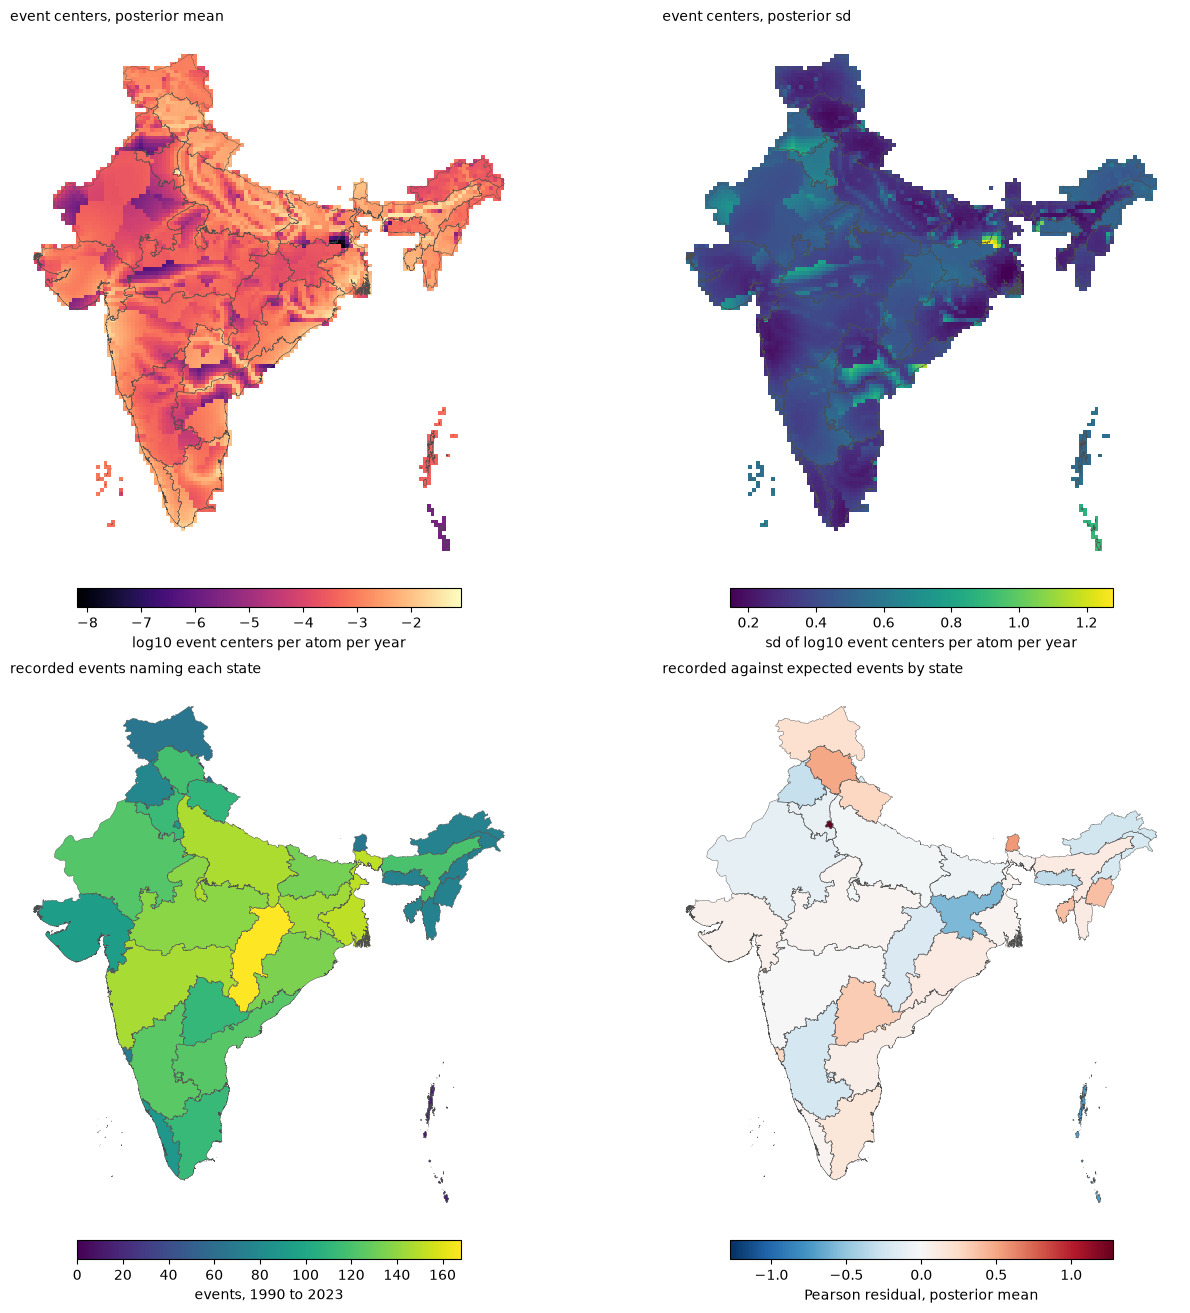

In [24]:
average_year_effect = np.log(np.exp(posterior["year_effect"]).mean("year"))
log10_rate = (posterior["log_rate"] + average_year_effect) / np.log(10)

# A recorded event names a state when its union reaches any of the state's atoms.
events_naming_state = np.zeros(n_states, dtype=int)
for atoms in event_union_atoms:
    events_naming_state[np.unique(state_of_atom[atoms])] += 1

draw_maps([(atom_cells.assign(value=log10_rate.mean(("chain", "draw")).to_numpy()), "magma", None,
            "event centers, posterior mean", "log10 event centers per atom per year"),
           (atom_cells.assign(value=log10_rate.std(("chain", "draw")).to_numpy()), "viridis", None,
            "event centers, posterior sd", "sd of log10 event centers per atom per year"),
           (units["ADM1"].assign(value=events_naming_state), "viridis", None,
            "recorded events naming each state", f"events, {FIRST_YEAR} to {LAST_YEAR}"),
           (units["ADM1"].assign(value=pearson_residual), "RdBu_r", symmetric_limits(pearson_residual),
            "recorded against expected events by state", "Pearson residual, posterior mean")],
          ncols=2)

### What sets the rate

Each term of the log rate $\log \lambda_a = \beta_0 + \sum_k \beta_k X_{a,k} + f(a) + u_{\mathrm{ADM1}(a)}$ on the map, at its posterior mean: the four covariate terms $\beta_k X_{a,k}$, the HSGP field $f$ and the state offsets $u$. All six are on the log rate's scale, and each colormap is centered on zero.

In [25]:
with pm.Model(coords=COORDS) as rate_terms_model:
    fitted_parameters()
    pm.Deterministic("covariate_term", covariates * rate_terms_model["slopes"], dims=("atom", "covariate"))

rate_terms = pm.compute_deterministics(posterior, model=rate_terms_model, var_names=["covariate_term"])

Output()

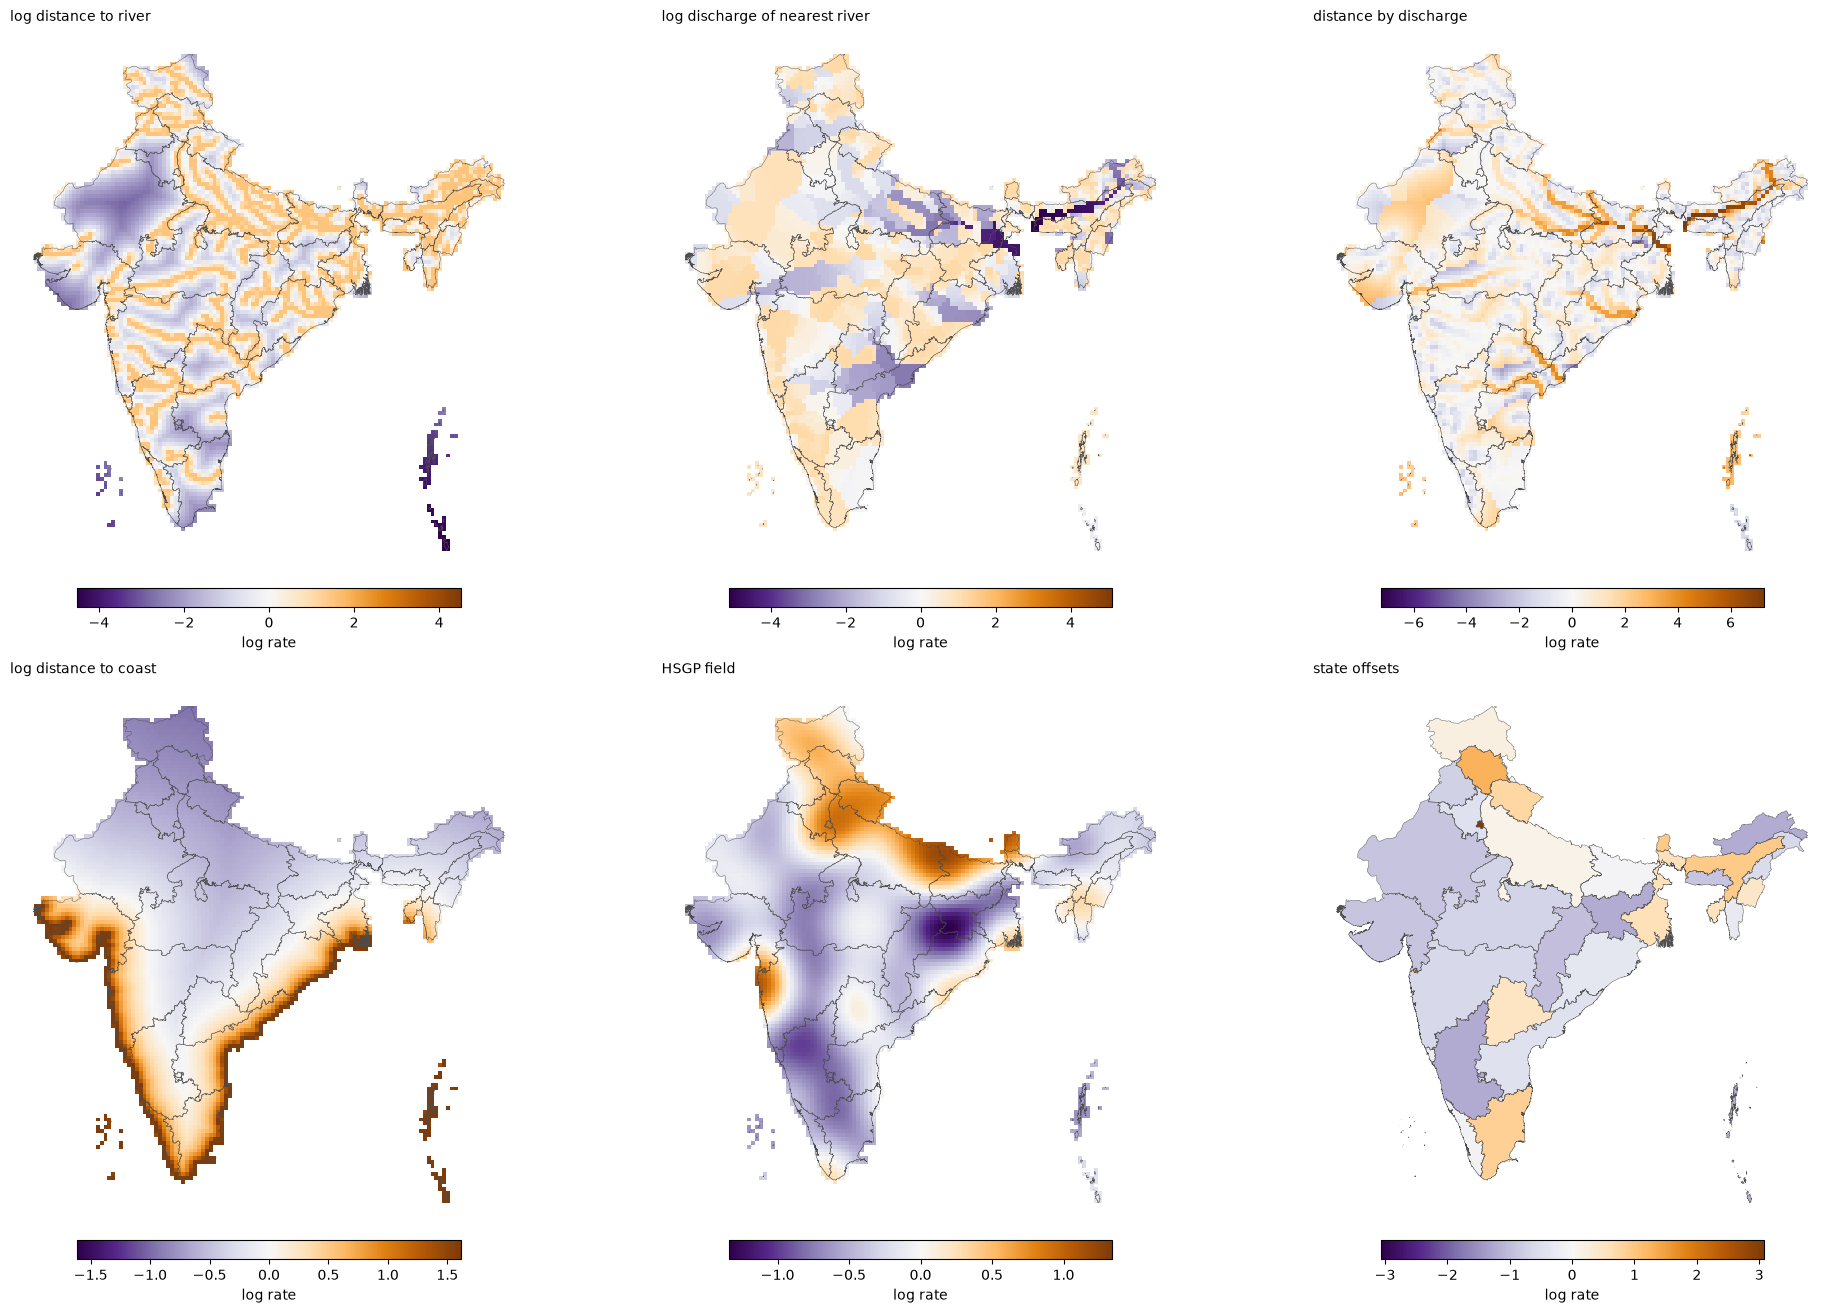

,mean,sd,eti90_lb,eti90_ub
slopes[log distance to river],-1.3,0.32,-1.8,-0.74
slopes[log discharge of nearest river],-1.2,0.38,-1.9,-0.61
slopes[distance by discharge],-1.4,0.32,-1.9,-0.89
slopes[log distance to coast],-0.66,0.25,-1,-0.25


In [26]:
covariate_terms = rate_terms["covariate_term"].mean(("chain", "draw")).to_numpy()
field_mean = posterior["field"].mean(("chain", "draw")).to_numpy()
state_offset_mean = posterior["ADM1_offset"].mean(("chain", "draw")).to_numpy()

draw_maps([*[(atom_cells.assign(value=covariate_terms[:, index]), "PuOr_r", symmetric_limits(covariate_terms[:, index]), name, "log rate")
             for index, name in enumerate(COVARIATE_NAMES)],
           (atom_cells.assign(value=field_mean), "PuOr_r", symmetric_limits(field_mean), "HSGP field", "log rate"),
           (units["ADM1"].assign(value=state_offset_mean), "PuOr_r", symmetric_limits(state_offset_mean), "state offsets", "log rate")],
          ncols=3)

az.summary(posterior, var_names=["slopes"], kind="stats", ci_prob=0.9).round(2)

### The year effect

The year effect $\eta_t = g(t) + \tau \epsilon_t$ on the rate of all events, with its smooth part $g(t)$, and the recorded events per year against their posterior predictive distribution, $N_t \sim \operatorname{Poisson}(\Lambda_t)$ at each draw's expected recorded events $\Lambda_t$.

In [27]:
with pm.Model(coords=COORDS) as recorded_events_model:
    fitted = fitted_parameters()
    expected_recorded = expected_recorded_per_year(rate=fitted["rate"],
                                                   parameters=fitted["indicators"],
                                                   class_probability=CLASS_PROBABILITY,
                                                   declaration=fitted["reporting"]["declaration"])
    pm.Poisson("recorded_events_replicate", mu=expected_recorded * pt.exp(fitted["effect"]), dims="year")

recorded_events_replicates = pm.sample_posterior_predictive(posterior,
                                                            model=recorded_events_model,
                                                            var_names=["recorded_events_replicate"],
                                                            random_seed=SEED).posterior_predictive["recorded_events_replicate"]

Sampling: [recorded_events_replicate]


Output()

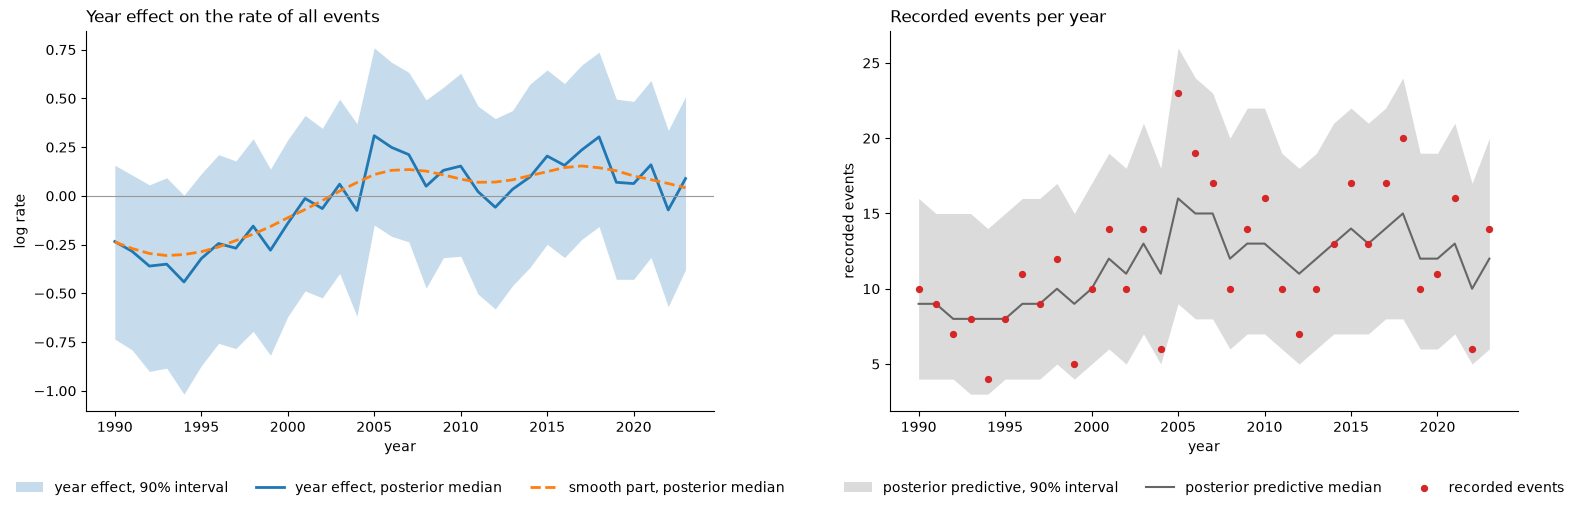

years outside the 90% predictive interval     0
years                                        34
dtype: int64

In [28]:
BAND = [0.05, 0.95]


def band_and_median(values):
    """The 90% interval and median over posterior draws."""
    quantiles = values.quantile([*BAND, 0.5], dim=("chain", "draw"))

    return quantiles.isel(quantile=0), quantiles.isel(quantile=1), quantiles.isel(quantile=2)


effect_low, effect_high, effect_median = band_and_median(posterior["year_effect"])
replicate_low, replicate_high, replicate_median = band_and_median(recorded_events_replicates)

figure, (effect_axis, count_axis) = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)

effect_axis.fill_between(years, effect_low, effect_high, color="C0", alpha=0.25, linewidth=0, label="year effect, 90% interval")
effect_axis.plot(years, effect_median, color="C0", linewidth=2.0, label="year effect, posterior median")
effect_axis.plot(years, posterior["year_smooth"].median(("chain", "draw")), color="C1", linewidth=2.0, linestyle="--", label="smooth part, posterior median")
effect_axis.axhline(0.0, color="0.6", linewidth=0.8)
effect_axis.set(xlabel="year", ylabel="log rate")
effect_axis.set_title("Year effect on the rate of all events", loc="left")

count_axis.fill_between(years, replicate_low, replicate_high, color="0.6", alpha=0.35, linewidth=0, label="posterior predictive, 90% interval")
count_axis.plot(years, replicate_median, color="0.4", linewidth=1.5, label="posterior predictive median")
count_axis.scatter(years, observed["annual"], color="C3", s=18, zorder=3, label="recorded events")
count_axis.set(xlabel="year", ylabel="recorded events")
count_axis.set_title("Recorded events per year", loc="left")

for axis in (effect_axis, count_axis):
    axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)

plt.show()

pd.Series({"years outside the 90% predictive interval": int(((observed["annual"] < replicate_low) | (observed["annual"] > replicate_high)).sum()),
           "years": YEARS})

### Posterior predictive checks

Two checks. The first simulates whole records and compares them with EM-DAT's, which tests the entry rule along with the counts. The second keeps the 400 recorded events and replicates their reported counts from the joint model, which tests the counts given each event's center and hazard.

#### Simulated records

A simulated record starts from every event the rate produces, recorded or not. Those have no fixed number, so they are drawn inside a `CustomDist` as one flat vector per posterior draw:

1. a count $N_{t,b} \sim \operatorname{Poisson}\left(e^{\eta_t} \sum_{a \in b} \lambda_a\right)$ for each year $t$ and exposure bin $b$, with each (year, bin) cell repeated that many times;
2. one hazard $H_e \sim \operatorname{Normal}(0, 1)$ per event, shared by its three counts, and each count from its normal on the model's scale;
3. EM-DAT's entry rule, a declaration with probability $\delta$ for an event below both thresholds, and the damage-reporting draw.

Sums over a record's events then have a fixed shape. Each simulated record is reduced to the histogram of its recorded events' $\log(1 + \text{count})$ on fixed edges, one per count, with damage only where it is written down. Deaths and people affected are compared with the record's events that report them, since the model does not say when those go unreported.

In [29]:
# The core shapes of event_inputs: (year, bin), (indicator, class, year, bin), (indicator), (indicator).
EVENT_SIGNATURE = "(y,b),(i,c,y,b),(i),(i)"


def event_inputs(fitted):
    """What a simulation of events reads from the fitted parameters, in the order of EVENT_SIGNATURE."""
    indicators = fitted["indicators"]

    return (rate_by_year_bin(fitted["rate"]) * pt.exp(fitted["effect"])[:, None],
            pt.stack([indicator_location(indicators, indicator) for indicator in range(len(INDICATORS))]),
            indicators["loading"],
            indicators["sd"])


def simulate_events(rate_by_bin, location, loading, sd, runs):
    """
    Every event, recorded or not, in ``runs`` runs of the record's years.

    Parameters
    ----------
    rate_by_bin : TensorVariable
        The rate of all events over (year, exposure bin), with the year effect.
    location : TensorVariable
        Each count's mean on the model's scale before the hazard, over (indicator, class, year, exposure bin).
    loading, sd : TensorVariable
        Each count's hazard loading and noise sd.
    runs : int
        Runs of the record's years to simulate.

    Returns
    -------
    run_year : TensorVariable
        Each event's run and year as one index, ``run * YEARS + year``.
    year_index : TensorVariable
        Each event's year.
    mean : TensorVariable
        Each count's mean at the event's hazard, over (indicator, event).
    values : TensorVariable
        Each count on the model's scale, over (indicator, event).
    """
    counts = pm.Poisson.dist(mu=pt.broadcast_to(rate_by_bin, (runs, YEARS, n_exposure_bins)))
    cell = pt.repeat(pt.arange(runs * YEARS * n_exposure_bins), counts.ravel())
    run_year, exposure_index = cell // n_exposure_bins, cell % n_exposure_bins
    year_index = run_year % YEARS
    event_class = pm.Categorical.dist(p=CLASS_PROBABILITY, size=cell.shape)

    hazard = pm.Normal.dist(size=cell.shape)
    mean = location[:, event_class, year_index, exposure_index] + loading[:, None] * hazard
    values = mean + sd[:, None] * pm.Normal.dist(size=mean.shape)

    return run_year, year_index, mean, values


def counts_from_scale(values, year_index):
    """Counts in their own units from the model's scale, over (indicator, event)."""
    return pt.stack([pt.expm1(values[DEATHS]),
                     pt.as_tensor(year_population)[year_index] * pm.math.invlogit(values[AFFECTED]),
                     pt.expm1(values[DAMAGE])])


def enter_record(year_index, mean, values, declaration, reporting_intercept, reporting_slope):
    """
    Which simulated events EM-DAT records.

    Returns
    -------
    entered : TensorVariable
        Whether each event enters the record.
    damage_written : TensorVariable
        Whether each event enters the record with its damage written down.
    """
    entered = ((values[DEATHS] >= pt.as_tensor(ENTRY_THRESHOLDS["deaths"])[year_index])
               | (values[AFFECTED] >= pt.as_tensor(ENTRY_THRESHOLDS["affected"])[year_index])
               | pt.eq(pm.Bernoulli.dist(p=declaration, size=year_index.shape), 1))
    written = pt.eq(pm.Bernoulli.dist(logit_p=reporting_intercept + reporting_slope * (mean[DAMAGE] - DAMAGE_REFERENCE)), 1)

    return entered, entered & written

In [30]:
MARK_BINS = 40

# The record's log(1 + count) per event, NaN where not reported, and histogram edges two log units past its range.
observed_log_counts = np.log1p(record[list(INDICATORS)].to_numpy().astype(float))
mark_edges = np.stack([np.linspace(np.nanmin(column) - 2.0, np.nanmax(column) + 2.0, MARK_BINS + 1) for column in observed_log_counts.T])


def simulated_record_marks_dist(rate_by_bin, location, loading, sd, declaration, reporting_intercept, reporting_slope, size):
    """A simulated record's histogram of log(1 + count) per indicator on ``mark_edges``, damage only where written down, over (indicator, mark bin)."""
    _, year_index, mean, values = simulate_events(rate_by_bin, location, loading, sd, runs=1)
    entered, damage_written = enter_record(year_index, mean, values, declaration, reporting_intercept, reporting_slope)
    log_counts = pt.log1p(counts_from_scale(values, year_index))

    # Values past the edges fall in the end bins.
    bin_index = pt.clip(pt.floor((log_counts - mark_edges[:, :1]) / np.diff(mark_edges[:, :2])).astype("int64"), 0, MARK_BINS - 1)
    weights = [entered, entered, damage_written]

    return pt.stack([pt.zeros(MARK_BINS)[bin_index[indicator]].inc(weights[indicator].astype("float64")) for indicator in range(len(INDICATORS))])


with pm.Model(coords=COORDS | {"mark_bin": np.arange(MARK_BINS)}) as simulated_record_model:
    fitted = fitted_parameters()
    pm.CustomDist("simulated_record_marks",
                  *event_inputs(fitted),
                  fitted["reporting"]["declaration"],
                  fitted["reporting"]["intercept"],
                  fitted["reporting"]["slope"],
                  dist=simulated_record_marks_dist,
                  signature=f"{EVENT_SIGNATURE},(),(),()->(i,m)",
                  dims=("indicator", "mark_bin"))

simulated_marks = pm.sample_posterior_predictive(posterior,
                                                 model=simulated_record_model,
                                                 var_names=["simulated_record_marks"],
                                                 random_seed=SEED).posterior_predictive["simulated_record_marks"]

Sampling: [simulated_record_marks]


Output()

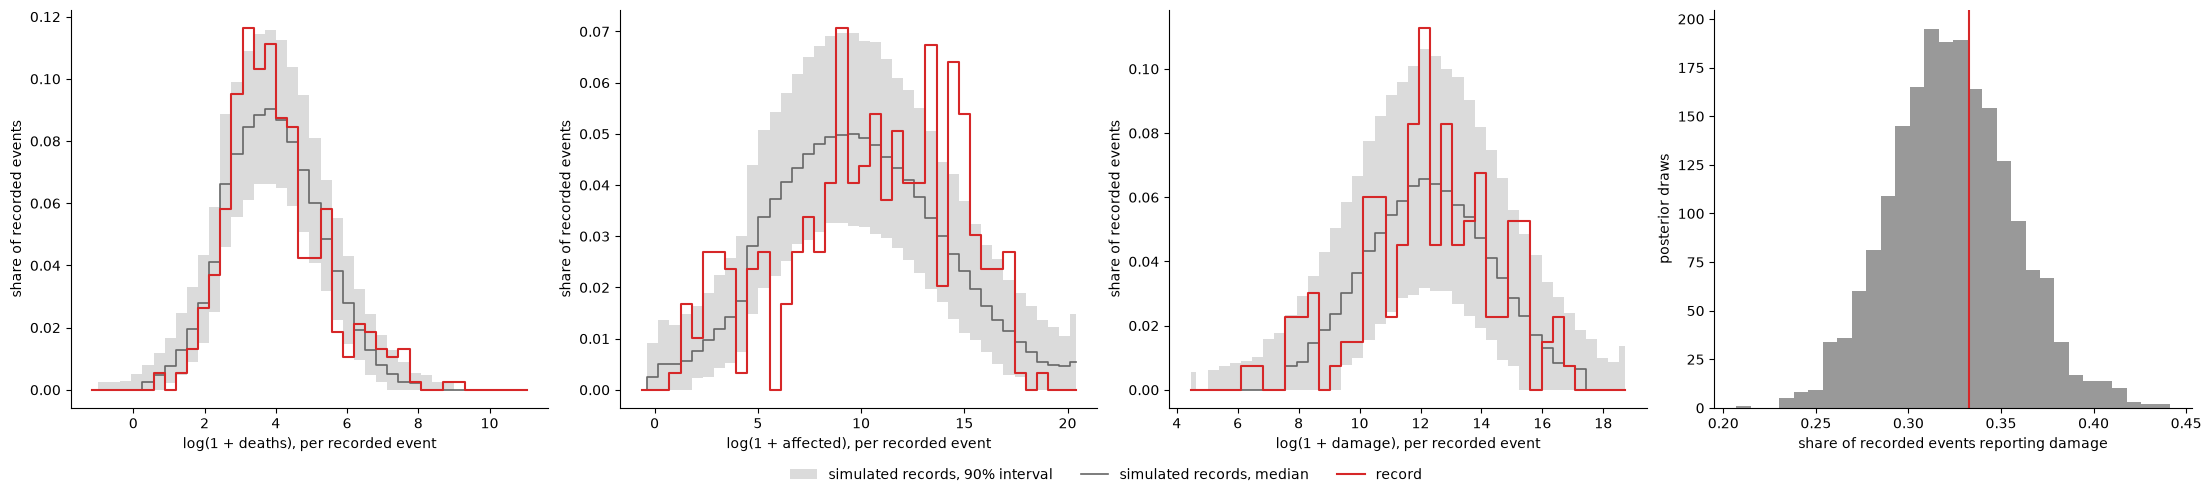

In [31]:
mark_centers = (mark_edges[:, :-1] + mark_edges[:, 1:]) / 2
simulated_mark_share = simulated_marks / simulated_marks.sum("mark_bin")
observed_marks = np.stack([np.histogram(column[~np.isnan(column)], bins=edges)[0] for column, edges in zip(observed_log_counts.T, mark_edges, strict=True)])
observed_mark_share = observed_marks / observed_marks.sum(axis=1, keepdims=True)

# Every recorded event has deaths in a simulated record, so the deaths row counts them.
simulated_recorded = simulated_marks.sel(indicator="deaths").sum("mark_bin")
simulated_damage_share = simulated_marks.sel(indicator="damage").sum("mark_bin") / simulated_recorded
observed_damage_share = observed["reported"][:, DAMAGE].mean()

figure, axes = plt.subplots(1, 4, figsize=(22, 4.5), constrained_layout=True)

for indicator, (axis, name) in enumerate(zip(axes[:3], INDICATORS, strict=True)):
    low, high, median = band_and_median(simulated_mark_share.isel(indicator=indicator))
    axis.fill_between(mark_centers[indicator], low, high, step="mid", color="0.6", alpha=0.35, linewidth=0, label="simulated records, 90% interval")
    axis.step(mark_centers[indicator], median, where="mid", color="0.4", linewidth=1.2, label="simulated records, median")
    axis.step(mark_centers[indicator], observed_mark_share[indicator], where="mid", color="C3", linewidth=1.5, label="record")
    axis.set(xlabel=f"log(1 + {name}), per recorded event", ylabel="share of recorded events")

axes[3].hist(simulated_damage_share.to_numpy().ravel(), bins=30, color="0.6")
axes[3].axvline(observed_damage_share, color="C3", linewidth=1.5)
axes[3].set(xlabel="share of recorded events reporting damage", ylabel="posterior draws")

handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles=handles, labels=labels, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=len(labels), frameon=False)
plt.show()

In [32]:
# The model's own expected recorded events checks the simulation: the two should agree to within simulation noise.
record_summaries = xr.Dataset({"recorded events, simulated records": simulated_recorded,
                               "recorded events, model's expectation": posterior["expected_recorded"].sum("year"),
                               "share reporting damage, simulated records": simulated_damage_share})

pd.concat([az.summary(record_summaries, kind="stats", ci_prob=0.9),
           pd.Series([len(record), len(record), observed_damage_share], index=list(record_summaries.data_vars), name="record")],
          axis=1).round(2)

,mean,sd,eti90_lb,eti90_ub,record
"recorded events, simulated records",401.55,28.32,357.00,450.00,400.00
"recorded events, model's expectation",401.71,20.28,367.55,435.47,400.00
"share reporting damage, simulated records",0.32,0.03,0.27,0.38,0.33


#### The recorded events' marks

`recover` draws each recorded event's center bin $b_e$ and hazard node $k_e$ from their conditional posterior at each draw,

$$p(b_e, k_e \mid \theta, \text{marks}_e) \propto \frac{\sum_{a \in U_e \cap b_e} \lambda_a}{\sum_{a \in U_e} \lambda_a}\, w_{k_e}\, p(\text{marks}_e \mid b_e, h_{k_e}, \theta),$$

and the joint model, with those two turned back into variables by `unmarginalize`, replicates each event's reported counts and its damage report. Counts are compared on the model's scale. If the hazard model is right, the recovered hazards pooled over events take node $k$ with a share close to its weight $w_k$.

In [33]:
recovered = recover(xr.DataTree.from_dict({"posterior": posterior}), model=joint_model, random_seed=SEED)

unmarginalized_model = unmarginalize(joint_model)
mark_names = [variable.name for variable in unmarginalized_model.observed_RVs if variable.name.startswith(("log_", "damage_reported_"))]
mark_replicates = pm.sample_posterior_predictive(recovered,
                                                 model=unmarginalized_model,
                                                 var_names=mark_names,
                                                 random_seed=SEED).posterior_predictive

Sampling: [center_affected, center_affected_damage, center_deaths, center_deaths_affected, center_deaths_affected_below, center_deaths_affected_damage, center_deaths_below, center_deaths_damage, center_none_below, hazard_node_affected, hazard_node_affected_damage, hazard_node_deaths, hazard_node_deaths_affected, hazard_node_deaths_affected_below, hazard_node_deaths_affected_damage, hazard_node_deaths_below, hazard_node_deaths_damage, hazard_node_none_below]
Sampling: [damage_reported_affected, damage_reported_affected_damage, damage_reported_deaths, damage_reported_deaths_affected, damage_reported_deaths_affected_below, damage_reported_deaths_affected_damage, damage_reported_deaths_below, damage_reported_deaths_damage, damage_reported_none_below, log_affected_affected, log_affected_affected_damage, log_affected_deaths_affected, log_affected_deaths_affected_below, log_affected_deaths_affected_damage, log_damage_affected_damage, log_damage_deaths_affected_damage, log_damage_deaths_damage

Output()

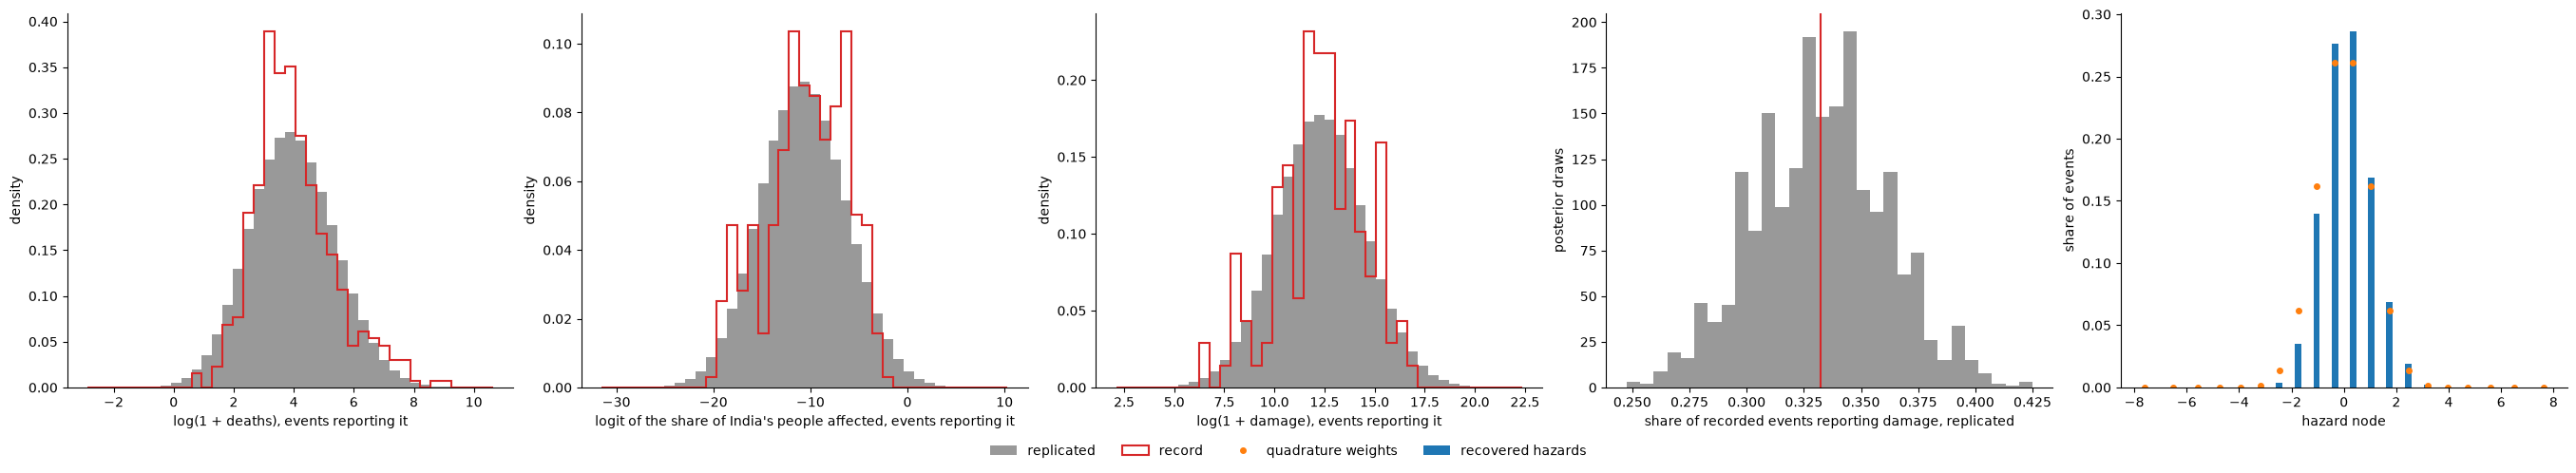

In [34]:
SCALE_LABELS = {"deaths": "log(1 + deaths)", "affected": "logit of the share of India's people affected", "damage": "log(1 + damage)"}


def pooled_marks(name):
    """
    A reported count's values on the model's scale, pooled over the reporting groups that report it.

    Returns
    -------
    replicated : ndarray
        The replicated values over every draw and event.
    recorded : ndarray
        The record's values.
    """
    indicator = list(INDICATORS).index(name)
    groups = [group for group in observed["groups"] if group["reported"][indicator]]
    replicated = np.concatenate([mark_replicates[f"log_{name}_{group['name']}"].to_numpy().ravel() for group in groups])
    recorded = np.concatenate([observed["values"][group["events"], indicator] for group in groups])

    return replicated, recorded


# Over (chain, draw).
replicated_damage_share = sum(mark_replicates[f"damage_reported_{group['name']}"].sum(f"event_{group['name']}") for group in observed["groups"]) / len(record)
recovered_nodes = np.concatenate([recovered.posterior[f"hazard_node_{group['name']}"].to_numpy().ravel() for group in observed["groups"]])

figure, axes = plt.subplots(1, 5, figsize=(27, 4.5), constrained_layout=True)

for axis, name in zip(axes[:3], INDICATORS, strict=True):
    replicated, recorded = pooled_marks(name)
    bins = np.linspace(min(replicated.min(), recorded.min()), max(replicated.max(), recorded.max()), 40)
    axis.hist(replicated, bins=bins, density=True, color="0.6", label="replicated")
    axis.hist(recorded, bins=bins, density=True, histtype="step", color="C3", linewidth=1.5, label="record")
    axis.set(xlabel=f"{SCALE_LABELS[name]}, events reporting it", ylabel="density")

axes[3].hist(replicated_damage_share.to_numpy().ravel(), bins=30, color="0.6")
axes[3].axvline(observed["reported"][:, DAMAGE].mean(), color="C3", linewidth=1.5)
axes[3].set(xlabel="share of recorded events reporting damage, replicated", ylabel="posterior draws")

axes[4].bar(hazard_nodes, np.bincount(recovered_nodes, minlength=QUADRATURE_NODES) / recovered_nodes.size, width=0.25, color="C0", label="recovered hazards")
axes[4].plot(hazard_nodes, hazard_weights, "o", color="C1", markersize=4, label="quadrature weights")
axes[4].set(xlabel="hazard node", ylabel="share of events")

handles, labels = axes[0].get_legend_handles_labels()
node_handles, node_labels = axes[4].get_legend_handles_labels()
figure.legend(handles=handles + node_handles,
              labels=labels + node_labels,
              loc="upper center",
              bbox_to_anchor=(0.5, 0.0),
              ncol=4,
              frameon=False)
plt.show()

### Outputs by state

Each state's expected yearly damage, deaths and people affected over every event, recorded or not, averaged over the record's years. Before its hazard, an event's count $j$ at year $t$ and exposure bin $b$ is centered on $\mu^0_{j,t,b} = \alpha_j + e_j x_b + v_j g_t$, and the hazard and the noise together give it sd $\sigma_j = \sqrt{b_j^2 + s_j^2}$ on the model's scale. So

$$\begin{aligned}
E[\text{deaths}] &= \exp\left(\mu^0_\text{deaths} + \sigma_\text{deaths}^2 / 2\right) - 1, \qquad \text{and likewise for damage}, \\
E[\text{affected}] &= P_t \sum_k w_k\, \operatorname{logit}^{-1}\left(\mu^0_\text{affected} + \sigma_\text{affected} h_k\right),
\end{aligned}$$

and state $S$'s yearly total is $\frac{1}{34} \sum_t \sum_b e^{\eta_t} \lambda_{S,b}\, E[\cdot]$, with $\lambda_{S,b}$ the rate summed over the state's atoms in bin $b$.

In [35]:
def count_spread(indicators, indicator):
    """A count's sd on the model's scale around its location, the hazard's loading and the noise together."""
    return pt.sqrt(indicators["loading"][indicator] ** 2 + indicators["sd"][indicator] ** 2)


def state_yearly_total(yearly_rate, per_event):
    """Each state's yearly total, over every event and averaged over the record's years, of a per-event quantity over (year, exposure bin)."""
    return (yearly_rate * per_event[:, None, :]).sum(axis=(0, 2)) / YEARS


with pm.Model(coords=COORDS) as outputs_model:
    fitted = fitted_parameters()
    indicators = fitted["indicators"]
    yearly_rate = yearly_rate_by_state(fitted["rate"], fitted["effect"])

    mean_deaths = over_classes(pt.expm1(indicator_location(indicators, DEATHS) + count_spread(indicators, DEATHS) ** 2 / 2))
    mean_damage = over_classes(pt.expm1(indicator_location(indicators, DAMAGE) + count_spread(indicators, DAMAGE) ** 2 / 2))
    mean_affected_share = over_classes((pm.math.invlogit(indicator_location(indicators, AFFECTED)[..., None]
                                                         + count_spread(indicators, AFFECTED) * hazard_nodes)
                                        * hazard_weights).sum(axis=-1))

    pm.Deterministic("expected_yearly_damage", state_yearly_total(yearly_rate, mean_damage) / 1e6, dims="ADM1")
    pm.Deterministic("expected_yearly_deaths", state_yearly_total(yearly_rate, mean_deaths), dims="ADM1")
    pm.Deterministic("expected_yearly_affected", state_yearly_total(yearly_rate, year_population[:, None] * mean_affected_share) / 1e6, dims="ADM1")

state_outputs = pm.compute_deterministics(posterior,
                                          model=outputs_model,
                                          var_names=["expected_yearly_damage", "expected_yearly_deaths", "expected_yearly_affected"])

Output()

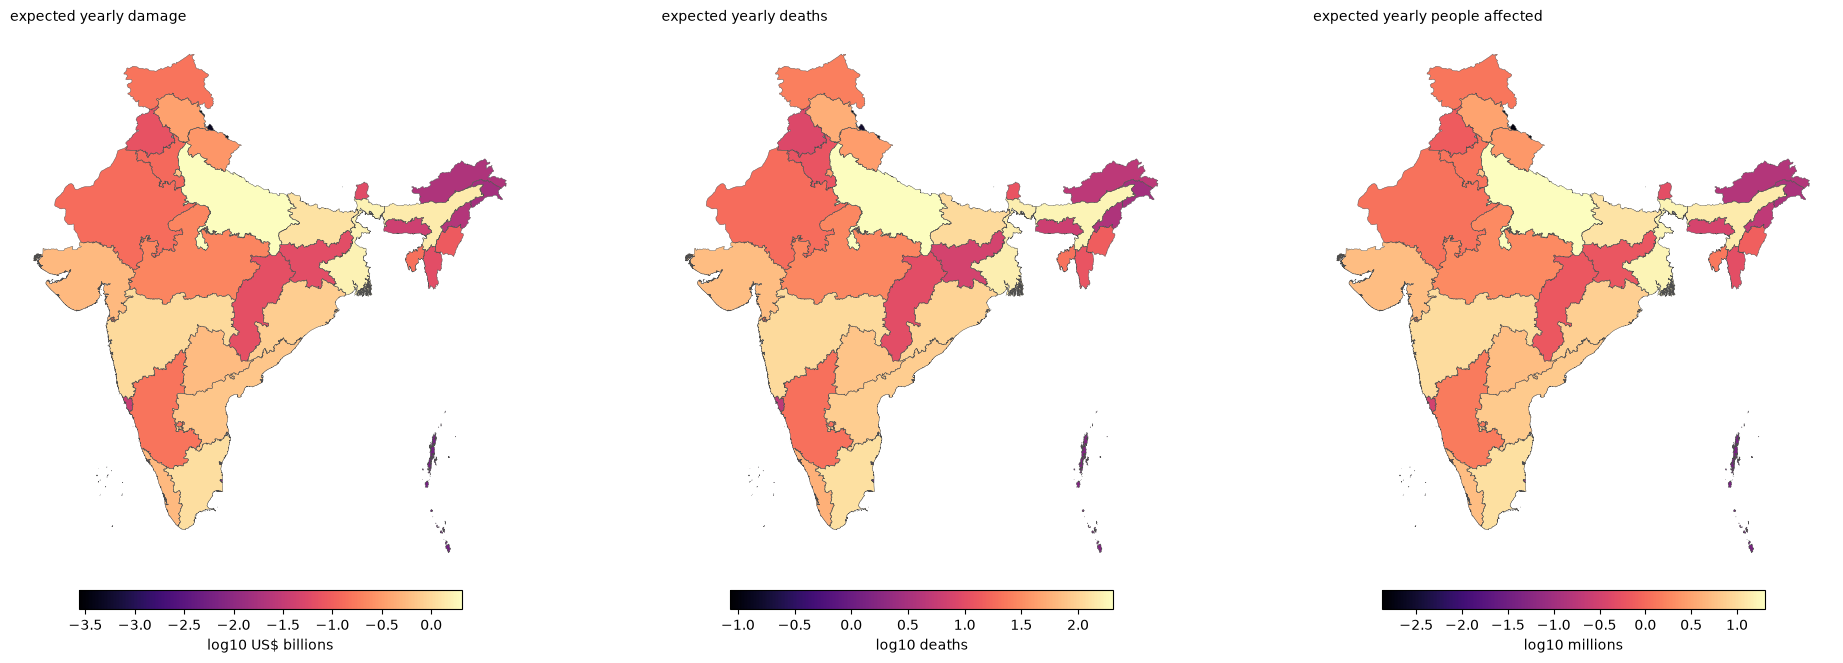

,mean,sd,eti90_lb,eti90_ub
expected_yearly_damage,15,5.4,8.2,25
expected_yearly_deaths,1700,190,1400,2000
expected_yearly_affected,140,35,90,200


In [36]:
STATE_OUTPUTS = {"expected_yearly_damage": ("expected yearly damage", "log10 US$ billions"),
                 "expected_yearly_deaths": ("expected yearly deaths", "log10 deaths"),
                 "expected_yearly_affected": ("expected yearly people affected", "log10 millions")}


def log10_state_mean(name):
    """A state output's posterior mean on log10, NaN for states with no atoms."""
    mean = state_outputs[name].mean(("chain", "draw")).to_numpy()

    return np.log10(np.where(mean > 0, mean, np.nan))


draw_maps([(units["ADM1"].assign(value=log10_state_mean(name)), "magma", None, title, label) for name, (title, label) in STATE_OUTPUTS.items()],
          ncols=3)

# India's totals: damage in US$ billions, people affected in millions.
az.summary(state_outputs.sum("ADM1"), kind="stats", ci_prob=0.9).round(1)

## Damage curves

Return levels of the damage of a year's largest event, recorded or not, for India and for each state. With $d$ a level of log damage, the yearly rate of events past it in state $S$ is

$$\Lambda_S(d) = \frac{1}{34} \sum_t \sum_b e^{\eta_t} \lambda_{S,b} \left[1 - \Phi\left(\frac{d - \mu^0_{\text{damage},t,b}}{\sigma_\text{damage}}\right)\right],$$

and India's is the sum over states. A year's largest damage exceeds $d$ with probability $1 - e^{-\Lambda(d)}$, so the return level for a period of $T$ years solves $\Lambda(d) = -\log(1 - 1/T)$. `pt.interp` inverts $\Lambda$ on a grid of 361 damage levels, from 400 thousand to 26 trillion US dollars.

In [37]:
RETURN_PERIODS = np.array([2, 5, 10, 25, 50, 100, 200])
CURVE_PERIODS = np.geomspace(1.2, 500.0, 120)
MAP_RETURN_PERIOD = 100
# On log(1 + damage in thousands of US$).
DAMAGE_LEVELS = np.linspace(6.0, 24.0, 361)


def billions(log_damage):
    """US$ billions from log(1 + damage in thousands of US$)."""
    return pt.expm1(log_damage) / 1e6


def return_levels(exceedance_rate, return_periods):
    """
    The log damage a year's largest event exceeds with probability 1 / T, for each T in ``return_periods``.

    NaN where no year reaches the lowest of DAMAGE_LEVELS that often.
    """
    target = -np.log1p(-1.0 / np.asarray(return_periods, dtype=float))
    levels = pt.interp(target, exceedance_rate[::-1], DAMAGE_LEVELS[::-1])

    return pt.switch(target > exceedance_rate[0], np.nan, levels)


with pm.Model(coords=COORDS | {"return_period": RETURN_PERIODS, "curve_period": CURVE_PERIODS}) as curves_model:
    fitted = fitted_parameters()
    indicators = fitted["indicators"]
    yearly_rate = yearly_rate_by_state(fitted["rate"], fitted["effect"])

    # Each state's yearly rate of events past each damage level, over (state, damage level).
    damage_tail = over_classes(normal_cdf((indicator_location(indicators, DAMAGE)[..., None] - DAMAGE_LEVELS) / count_spread(indicators, DAMAGE)))
    state_exceedance = pt.tensordot(yearly_rate, damage_tail, axes=[[0, 2], [0, 1]]) / YEARS
    india_exceedance = state_exceedance.sum(axis=0)

    pm.Deterministic("india_return_level", billions(return_levels(india_exceedance, RETURN_PERIODS)), dims="return_period")
    pm.Deterministic("india_return_curve", billions(return_levels(india_exceedance, CURVE_PERIODS)), dims="curve_period")
    pm.Deterministic("state_return_level",
                     pt.stack([billions(return_levels(state_exceedance[state], [MAP_RETURN_PERIOD]))[0] for state in range(n_states)]),
                     dims="ADM1")

damage_curves = pm.compute_deterministics(posterior,
                                          model=curves_model,
                                          var_names=["india_return_level", "india_return_curve", "state_return_level"])

Output()

In [38]:
india_levels = damage_curves["india_return_level"]

pd.DataFrame({"posterior median": india_levels.median(("chain", "draw")).to_series(),
              "5th percentile": india_levels.quantile(0.05, dim=("chain", "draw")).to_series(),
              "95th percentile": india_levels.quantile(0.95, dim=("chain", "draw")).to_series()}).rename_axis("return period, years").round(2)

,posterior median,5th percentile,95th percentile
"return period, years",,,
2,2.62,1.78,4.05
5,9.09,5.85,15.31
10,18.44,11.27,33.05
25,41.56,23.62,79.73
50,72.35,39.28,147.84
100,121.43,62.66,261.53
200,197.24,97.71,449.57


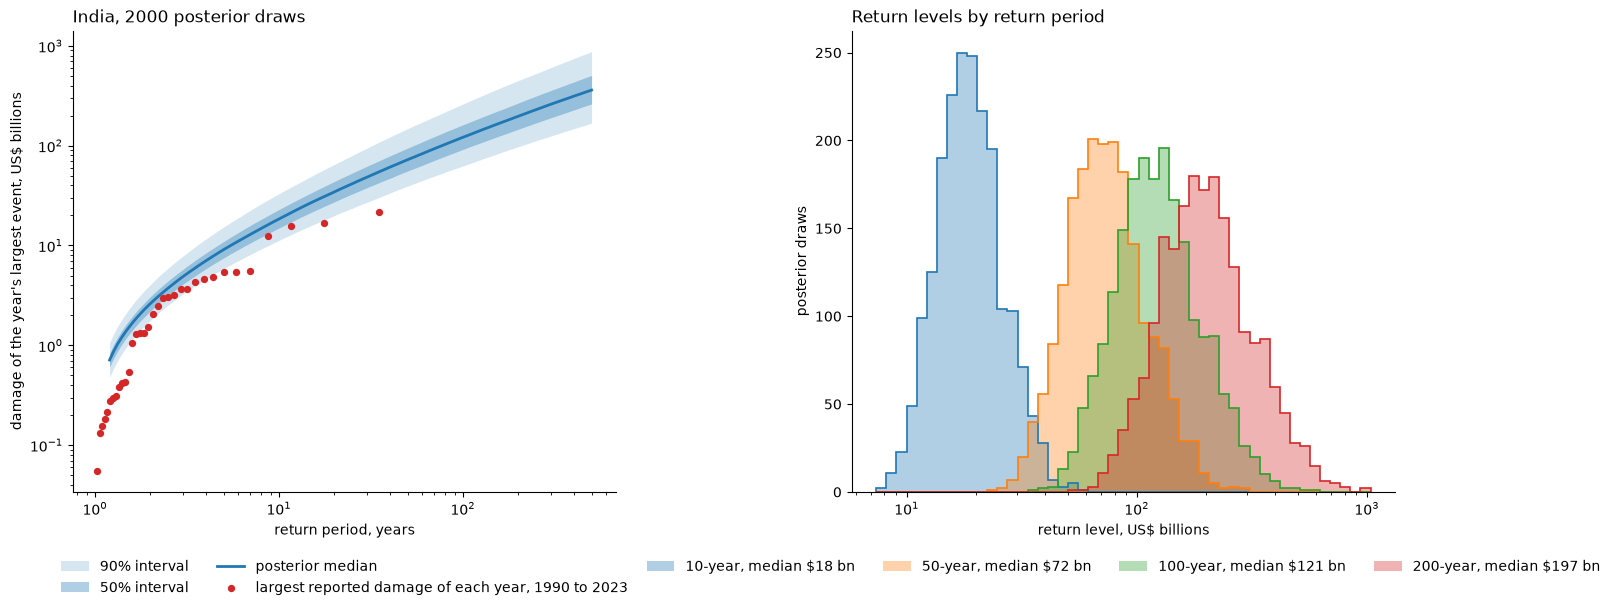

In [39]:
DISTRIBUTION_PERIODS = [10, 50, 100, 200]

curves = damage_curves["india_return_curve"]
band_90 = curves.quantile([0.05, 0.95], dim=("chain", "draw"))
band_50 = curves.quantile([0.25, 0.75], dim=("chain", "draw"))
period_levels = india_levels.sel(return_period=DISTRIBUTION_PERIODS)

# The record's largest reported damage each year, at Weibull plotting positions over all of its years. Most events report no
# damage, so these are lower bounds on each year's largest damage.
yearly_largest = (np.expm1(pd.Series(observed["values"][:, DAMAGE] * observed["reported"][:, DAMAGE])
                           .groupby(observed["year"]).max()
                           .reindex(range(YEARS), fill_value=0.0)
                           .sort_values(ascending=False)
                           .to_numpy()) / 1e6)
plotting_periods = (YEARS + 1) / np.arange(1, YEARS + 1)
has_damage = yearly_largest > 0

figure, (curve_axis, distribution_axis) = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)

curve_axis.fill_between(CURVE_PERIODS, *band_90, color="C0", alpha=0.18, linewidth=0, label="90% interval")
curve_axis.fill_between(CURVE_PERIODS, *band_50, color="C0", alpha=0.35, linewidth=0, label="50% interval")
curve_axis.plot(CURVE_PERIODS, curves.median(("chain", "draw")), color="C0", linewidth=2.0, label="posterior median")
curve_axis.scatter(plotting_periods[has_damage],
                   yearly_largest[has_damage],
                   color="C3",
                   s=18,
                   zorder=3,
                   label=f"largest reported damage of each year, {FIRST_YEAR} to {LAST_YEAR}")
# Both axes span two or more orders of magnitude.
curve_axis.set(xscale="log",
               yscale="log",
               xlabel="return period, years",
               ylabel="damage of the year's largest event, US$ billions")
curve_axis.set_title(f"India, {curves.sizes['chain'] * curves.sizes['draw']} posterior draws", loc="left")
curve_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)

level_bins = np.geomspace(period_levels.min().item(), period_levels.max().item(), 50)
for index, period in enumerate(DISTRIBUTION_PERIODS):
    levels = period_levels.sel(return_period=period).to_numpy().ravel()
    distribution_axis.hist(levels,
                           bins=level_bins,
                           histtype="stepfilled",
                           alpha=0.35,
                           color=f"C{index}",
                           label=f"{period}-year, median ${np.median(levels):.0f} bn")
    distribution_axis.hist(levels, bins=level_bins, histtype="step", color=f"C{index}", linewidth=1.2)
distribution_axis.set(xscale="log",
                      xlabel="return level, US$ billions",
                      ylabel="posterior draws")
distribution_axis.set_title("Return levels by return period", loc="left")
distribution_axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=len(DISTRIBUTION_PERIODS), frameon=False)

plt.show()

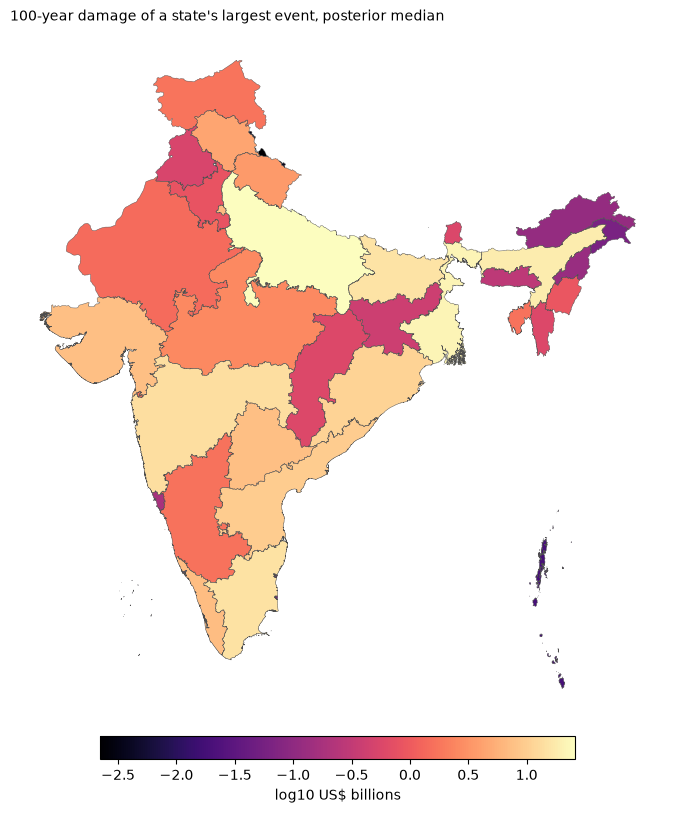

In [40]:
state_levels = damage_curves["state_return_level"]

# NaN where a state's largest event never reaches the lowest damage level that often, in any draw.
reaches_grid = state_levels.notnull().any(("chain", "draw")).to_numpy()
state_level_median = np.full(n_states, np.nan)
state_level_median[reaches_grid] = state_levels.isel(ADM1=reaches_grid).median(("chain", "draw"), skipna=True).to_numpy()

draw_maps([(units["ADM1"].assign(value=np.log10(state_level_median)), "magma", None,
            f"{MAP_RETURN_PERIOD}-year damage of a state's largest event, posterior median", "log10 US$ billions")],
          ncols=1,
          panel_size=8)

### A year's totals

Each year's deaths, people affected and damage summed over every event, recorded or not, against probability percentile, at four years of the record. The events come from the same simulation as the simulated records, without the entry rule: each posterior draw simulates 100 runs of the record's years under each year's rate, exposure and income. Pooling every draw's runs gives the posterior predictive distribution of a year's total, and the spread of each draw's own quantile curve gives its uncertainty.

In [41]:
REPLICATES = 100


def annual_totals_dist(rate_by_bin, location, loading, sd, size):
    """Each run-year's deaths, people affected and damage summed over every event, over (run, year, indicator)."""
    run_year, year_index, _, values = simulate_events(rate_by_bin, location, loading, sd, runs=REPLICATES)
    totals = pt.zeros((REPLICATES * YEARS, len(INDICATORS)))[run_year].inc(counts_from_scale(values, year_index).T)

    return totals.reshape((REPLICATES, YEARS, len(INDICATORS)))


with pm.Model(coords=COORDS | {"replicate": np.arange(REPLICATES)}) as annual_totals_model:
    fitted = fitted_parameters()
    pm.CustomDist("annual_total",
                  *event_inputs(fitted),
                  dist=annual_totals_dist,
                  signature=f"{EVENT_SIGNATURE}->(r,y,i)",
                  dims=("replicate", "year", "indicator"))

annual_totals = pm.sample_posterior_predictive(posterior,
                                               model=annual_totals_model,
                                               var_names=["annual_total"],
                                               random_seed=SEED).posterior_predictive["annual_total"]

Sampling: [annual_total]


Output()

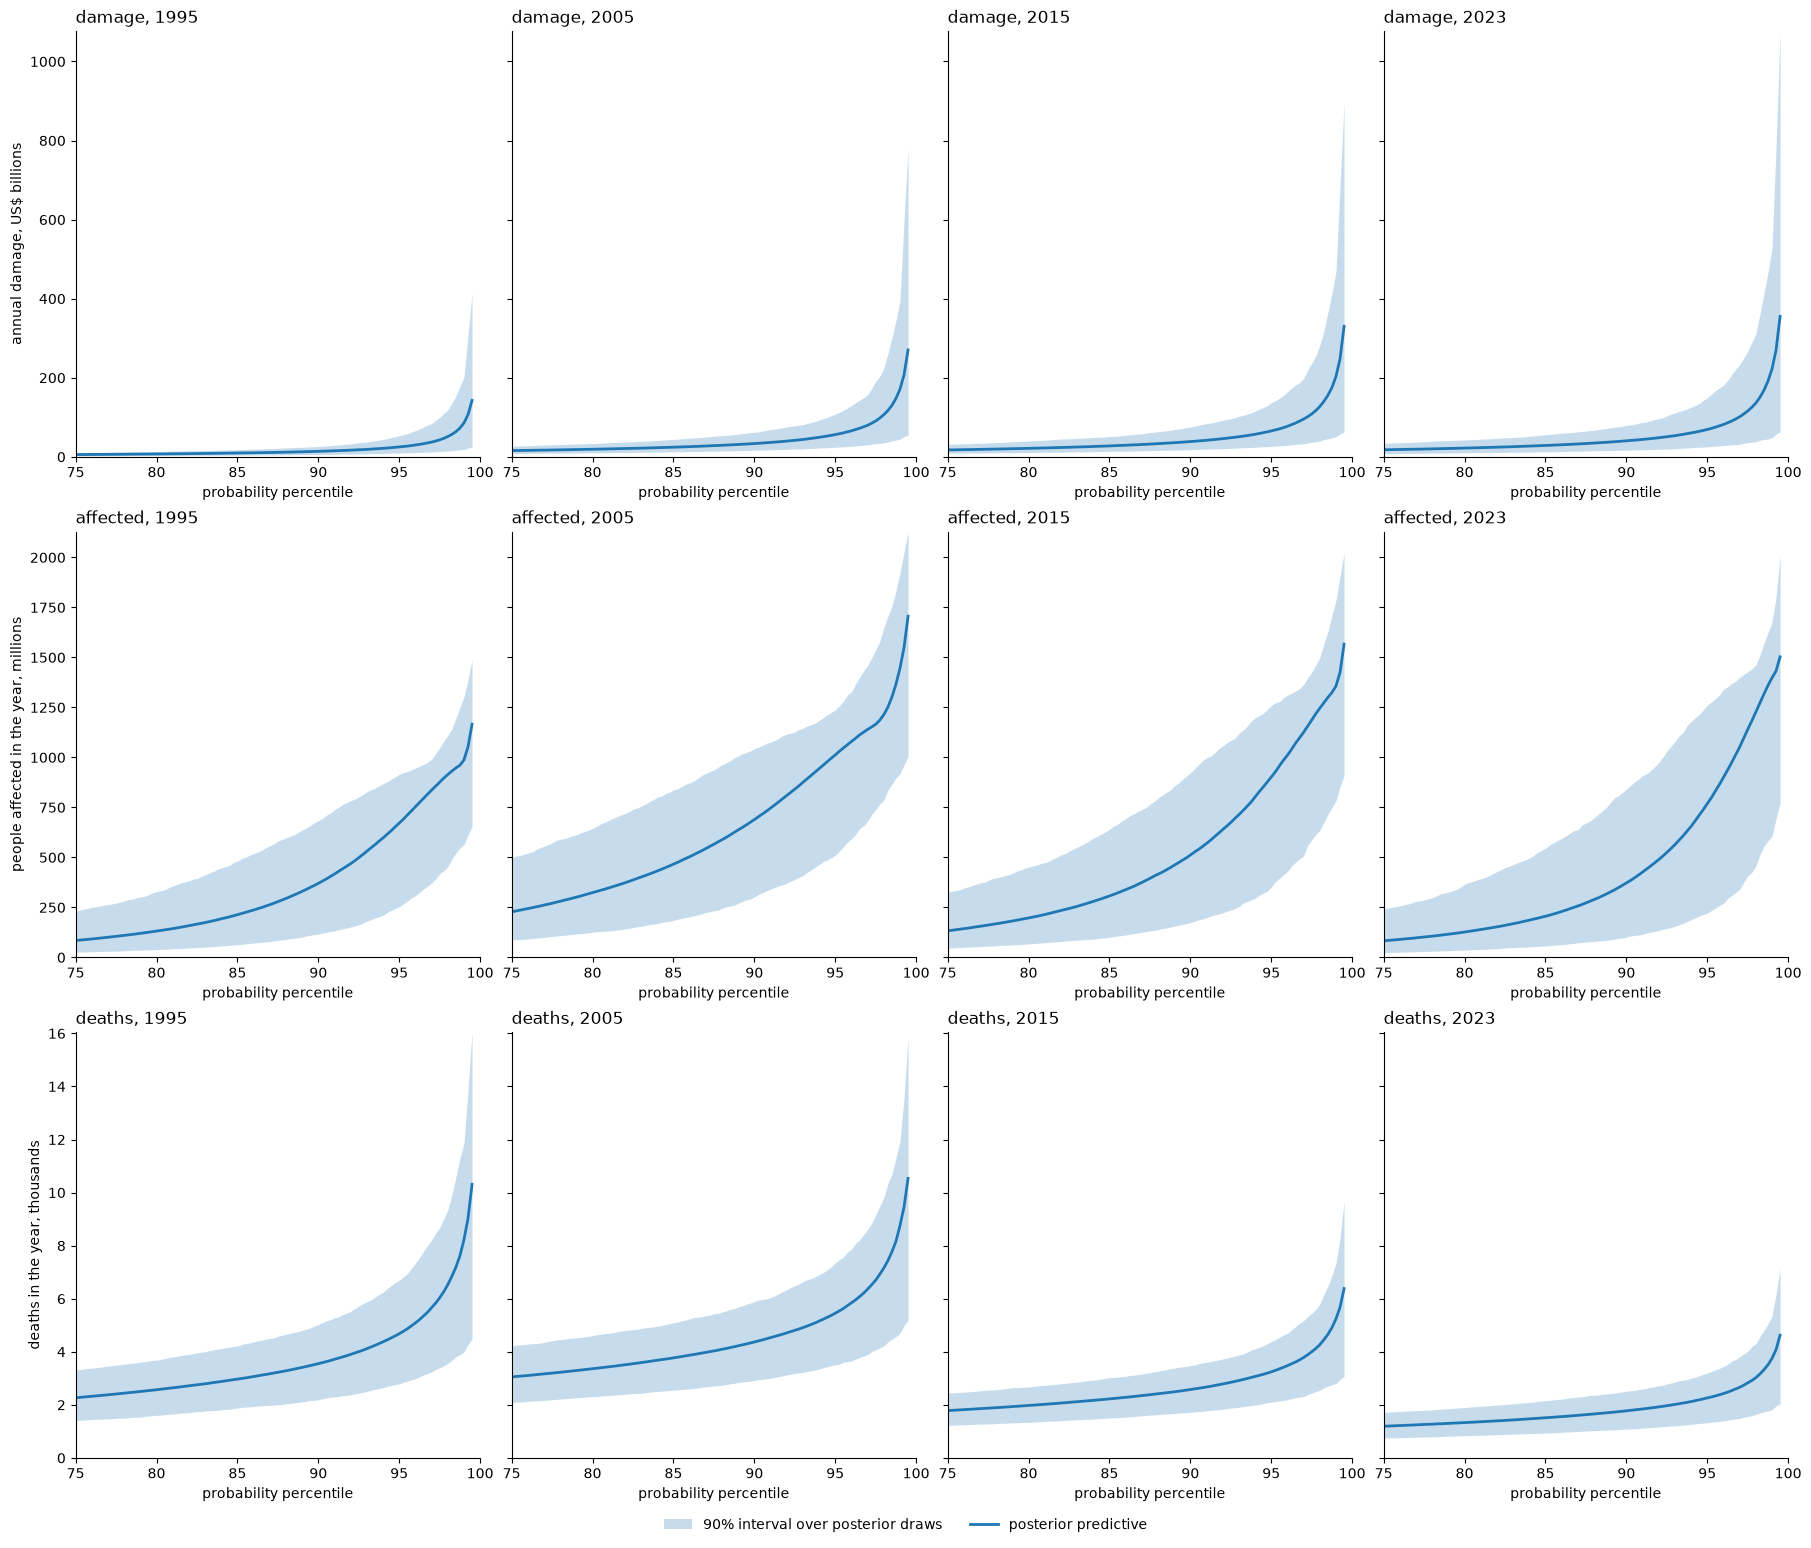

In [42]:
PANEL_YEARS = [1995, 2005, 2015, 2023]
PERCENTILES = np.linspace(0.0, 99.5, 400)
ZOOM_PERCENTILE = 75.0
# Each count's annual total in the units it is shown in: damage is recorded in thousands of US$.
DISPLAY_UNITS = {"damage": (1e6, "annual damage, US$ billions"),
                 "affected": (1e6, "people affected in the year, millions"),
                 "deaths": (1e3, "deaths in the year, thousands")}
zoomed = PERCENTILES >= ZOOM_PERCENTILE
# Over (chain, draw, replicate, year, indicator), each count in its display units.
panel_totals = xr.concat([annual_totals.sel(indicator=name, year=PANEL_YEARS) / scale for name, (scale, _) in DISPLAY_UNITS.items()], dim="indicator")

figure, axes = plt.subplots(len(DISPLAY_UNITS), len(PANEL_YEARS), figsize=(18, 15), sharey="row", constrained_layout=True)

for row, (name, (_, label)) in enumerate(DISPLAY_UNITS.items()):
    totals = panel_totals.sel(indicator=name)
    predictive_quantiles = totals.quantile(PERCENTILES / 100, dim=("chain", "draw", "replicate")).rename(quantile="percentile")
    draw_band = totals.quantile(PERCENTILES / 100, dim="replicate").rename(quantile="percentile").quantile(BAND, dim=("chain", "draw"))

    for axis, year in zip(axes[row], PANEL_YEARS, strict=True):
        axis.fill_between(PERCENTILES[zoomed],
                          draw_band.sel(quantile=BAND[0], year=year)[zoomed],
                          draw_band.sel(quantile=BAND[1], year=year)[zoomed],
                          color="C0",
                          alpha=0.25,
                          linewidth=0,
                          label="90% interval over posterior draws")
        axis.plot(PERCENTILES[zoomed],
                  predictive_quantiles.sel(year=year)[zoomed],
                  color="C0",
                  linewidth=2.0,
                  label="posterior predictive")
        axis.set(xlim=(ZOOM_PERCENTILE, 100),
                 ylim=(0, draw_band.sel(quantile=BAND[1]).isel(percentile=zoomed).max().item()),
                 xlabel="probability percentile")
        axis.set_title(f"{name}, {year}", loc="left")

    axes[row, 0].set_ylabel(label)

handles, labels = axes[0, 0].get_legend_handles_labels()
figure.legend(handles=handles,
              labels=labels,
              loc="upper center",
              bbox_to_anchor=(0.5, 0.0),
              ncol=len(labels),
              frameon=False)
plt.show()

In [43]:
TABLE_PERCENTILES = [50, 90, 95, 99]

(panel_totals.quantile(np.array(TABLE_PERCENTILES) / 100, dim=("chain", "draw", "replicate"))
 .assign_coords(quantile=[f"{percentile}th percentile" for percentile in TABLE_PERCENTILES])
 .to_series()
 .unstack("quantile")
 .rename_axis(index=["count", "year"], columns=None)
 .round(1))

50th percentile  90th percentile  95th percentile  \
count    year                                                      
damage   1995             2.20            13.90            25.00   
         2005             7.30            33.60            56.20   
         2015             7.90            38.60            65.60   
         2023             7.80            40.50            69.10   
affected 1995            14.10           370.40           671.40   
         2005            52.20           688.90          1012.30   
         2015            27.60           512.20           902.00   
         2023            15.60           372.20           768.80   
deaths   1995             1.40             3.60             4.70   
         2005             2.10             4.40             5.50   
         2015             1.20             2.60             3.20   
         2023             0.80             1.80             2.30   

               99th percentile  
count    year                   
damage   1995            85.60  
         2005           170.90  
         2015           203.40  
         2023           222.00  
affected 1995           987.30  
         2005          1445.80  
         2015          1356.80  
         2023          1397.80  
deaths   1995             8.20  
         2005             8.80  
         2015             5.20  
         2023             3.70